# Martial measurements @ 750 Hz (from raw PSD)

This notebook starts from the original PSD file and builds everything:
- load PSD
- orient/center data (floor->z, dominant intensity->x)
- visualize room (longx_dense)
- flow + phase slices
- SH extrapolation from near points to held-out measured points


In [82]:
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
from IPython.display import Image, display

def find_repo_root():
    p = Path.cwd().resolve()
    for _ in range(8):
        if (p/'.git').exists() or (p/'experiment').exists():
            return p
        p = p.parent
    return Path.cwd().resolve()

ROOT = find_repo_root()
PIPE_ROOT = ROOT/'final_pipe'
DATA = ROOT/'experiment'/'data'/'martial'

PSD = DATA/'psd'/'Martial measurements.psd'
PRJ = DATA/'prj'/'Martial measurements.prj'
ROOM_OBJ = DATA/'mesh'/'textured_output.obj'
ROOM_TEX = DATA/'mesh'/'textured_output.jpg'
ROOM_IMG = ROOT/'experiment'/'figs'/'room_mesh.png'
f0 = 750.0  # Frequency of interest in Hz

print('ROOT', ROOT)
print('PSD', PSD)
print('PRJ', PRJ)
print(f'f0 = {f0} Hz')


ROOT /Users/marcialsanchis/Desktop/PhD/ModeAir/MicroFLown/final_pipe
PSD /Users/marcialsanchis/Downloads/Martial measurements/Martial measurements.psd


## Load PRJ measurements (raw time data)
We skip Measurement1 and inspect labels/ranges.


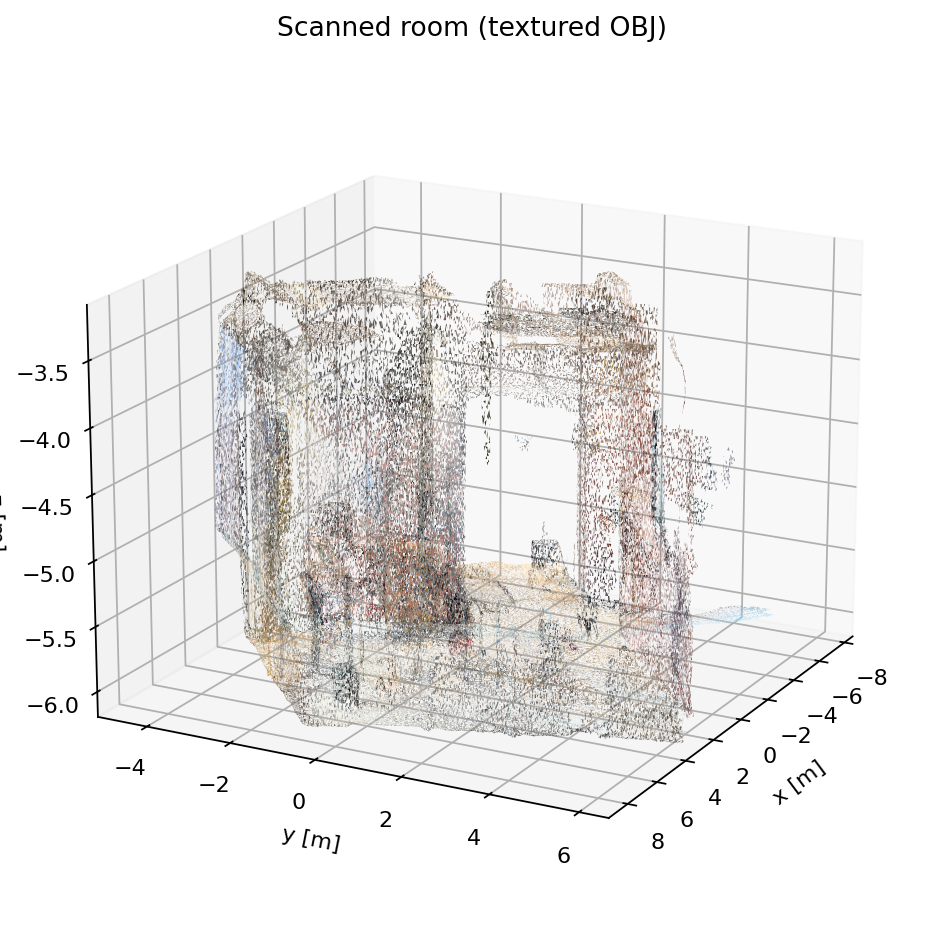

In [83]:
# If room image missing, render from OBJ/JPG
if not ROOM_IMG.exists():
    print('Rendering room...')
    OBJ = ROOM_OBJ
    TEX = ROOM_TEX
    script = ROOT/'scripts/run_show_room_mesh.py'
    cmd = f"python {script} --obj '{OBJ}' --texture '{TEX}' --stride 5 --max-faces 200000 --alpha 1.0 \
        --elev 18 --azim 28 --marker -0.21237767 4.6462193 1.0211926 \
        --center-to-marker --level-floor --align-long-axis --out {ROOM_IMG}"
    !{cmd}
if ROOM_IMG.exists():
    display(Image(filename=str(ROOM_IMG)))
else:
    print('Room image still missing:', ROOM_IMG)


In [84]:
import re
with h5py.File(PRJ, 'r') as f:
    meas = [k for k in f.keys() if k.startswith('Measurement')]
    print('measurements', meas)
    x = f['Measurement2/TimeData'][:, :200000]
    rms = np.sqrt(np.mean(x**2, axis=1))
    print('Measurement2 RMS per channel:', rms)
    raw = bytes(f['Measurement2/App_Settings'][()].flatten().tolist())
    words = re.findall(rb'[A-Za-z0-9_\-]{1,}', raw)
    hits = sorted({w.decode(errors='ignore') for w in words if w in [b'U',b'V',b'W',b'P',b'Pressure',b'Press']})
    print('App_Settings label hits:', hits)
    raw2 = bytes(f['Measurement2/ExtraLogData'][()].flatten().tolist())
    words2 = re.findall(rb'[A-Za-z0-9_\-]{1,}', raw2)
    hits2 = sorted({w.decode(errors='ignore') for w in words2 if w in [b'U',b'V',b'W',b'P',b'Pressure',b'Press']})
    print('ExtraLogData label hits:', hits2)
    obj = f['Measurement2/daqinfo/ObjInfo'][0]
    ranges = [ch['InputRange'].flatten().tolist() for ch in obj['Channel']]
    print('Channel input ranges:', ranges)
    # report data length per measurement
    for k in meas[1:]:
        n = f[f'{k}/TimeData'].shape[1]
        print(k, 'samples', n)


measurements ['Measurement1', 'Measurement2', 'Measurement3', 'Measurement4', 'Measurement5', 'Measurement6', 'Measurement7', 'Measurement8', 'Measurement9']
Measurement2 RMS per channel: [0.01120391 0.00203664 0.00317365 0.00391142 0.35658225 0.00804831]
App_Settings label hits: ['P', 'U', 'V', 'W']
ExtraLogData label hits: ['P', 'U', 'V', 'W']
Channel input ranges: [[-1.0, 1.0], [-1.0, 1.0], [-1.0, 1.0], [-1.0, 1.0], [-10.0, 10.0], [-1.0, 1.0]]
Measurement2 samples 9038880
Measurement3 samples 5292480
Measurement4 samples 4736160
Measurement5 samples 8651520
Measurement6 samples 9809280
Measurement7 samples 12950880
Measurement8 samples 8816160
Measurement9 samples 12701280


## Load PRJ measurements (raw time data)
We skip Measurement1 and use Measurement2..Measurement9. Channel 5 has larger input range (likely pressure).


## Use all measurements (2..9) to estimate 750 Hz magnitude
We skip Measurement1 and compute FFT magnitude at 750 Hz for P and U/V/W channels.


In [85]:
f0 =750
import numpy.fft as fft
with h5py.File(PRJ, 'r') as f:
    results = {}
    for k in [m for m in f.keys() if m.startswith('Measurement')][1:]:
        td = f[f'{k}/TimeData'][:]
        fs = float(f[f'{k}/daqinfo/ObjInfo'][0]['SampleRate'])
        n = td.shape[1]
        freqs = fft.rfftfreq(n, d=1/fs)
        fi = int(np.argmin(np.abs(freqs - f0)))
        # map channels by index (P assumed channel 5, U/V/W channels 1-3)
        Pch = td[4]  # channel 5 (0-based index 4)
        Uch = td[0]; Vch = td[1]; Wch = td[2]
        Pmag = np.abs(fft.rfft(Pch))[fi] / n
        Umag = np.abs(fft.rfft(Uch))[fi] / n
        Vmag = np.abs(fft.rfft(Vch))[fi] / n
        Wmag = np.abs(fft.rfft(Wch))[fi] / n
        results[k] = (Pmag, Umag, Vmag, Wmag)
    results


In [86]:
PRJ = Path('/Users/marcialsanchis/Downloads/Martial measurements/Martial measurements.prj')
with h5py.File(PRJ, 'r') as f:
    meas = [k for k in f.keys() if k.startswith('Measurement')]
    print('measurements', meas)
    # quick RMS for Measurement2 to see channel scaling
    x = f['Measurement2/TimeData'][:, :200000]
    rms = np.sqrt(np.mean(x**2, axis=1))
    print('Measurement2 RMS per channel:', rms)

# Mapping assumption: channels 1-3 = U,V,W; channel 5 = P (higher range).
u_idx = [0,1,2]
p_idx = 4
print('Assumed mapping: U/V/W=', u_idx, 'P=', p_idx)


measurements ['Measurement1', 'Measurement2', 'Measurement3', 'Measurement4', 'Measurement5', 'Measurement6', 'Measurement7', 'Measurement8', 'Measurement9']
Measurement2 RMS per channel: [0.01120391 0.00203664 0.00317365 0.00391142 0.35658225 0.00804831]
Assumed mapping: U/V/W= [0, 1, 2] P= 4


## Room context (longx_dense)


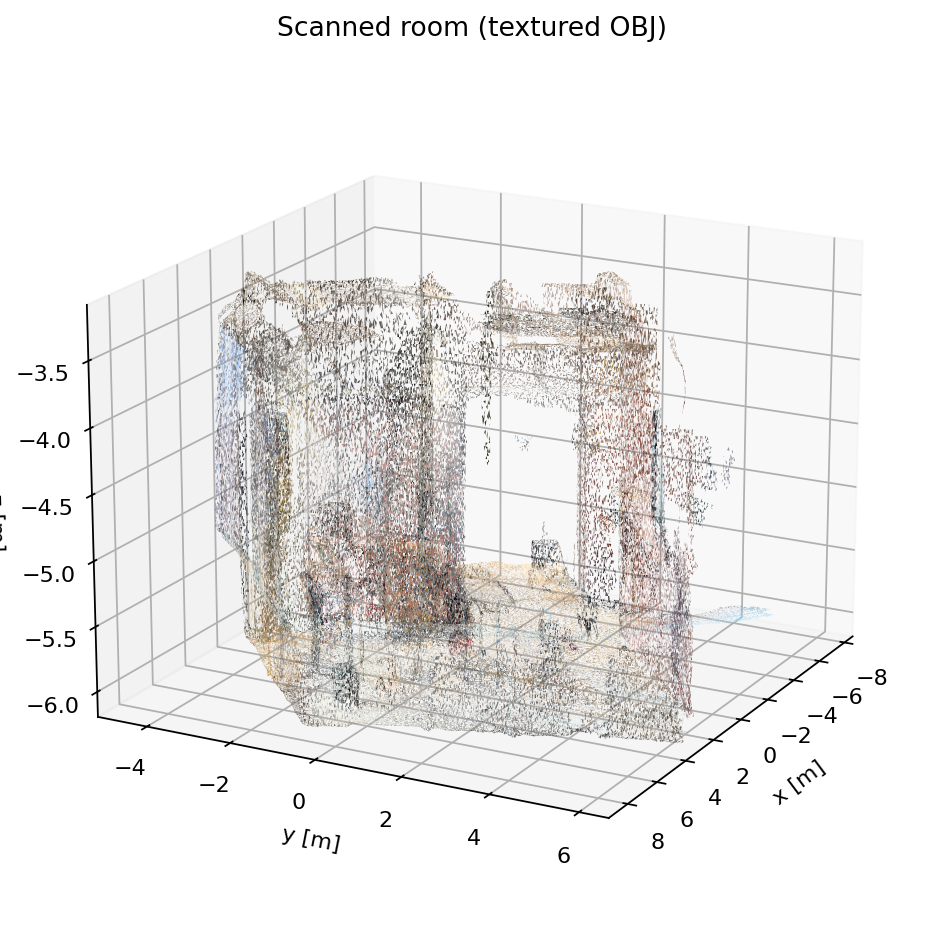

In [87]:
if ROOM_IMG.exists():
    display(Image(filename=str(ROOM_IMG)))
else:
    print('Room image not found:', ROOM_IMG)


## Load PSD and orient (floor->z, dominant intensity->x)
We also center on the source proxy (highest |P| at high frequencies).


In [88]:
f0 = 750.0
with h5py.File(PSD, 'r') as f:
    g = f['Process1']
    freq = np.array(g['FreqVar']).ravel()
    pos_raw = np.array(g['datPostition']).T
    fi = int(np.argmin(np.abs(freq - f0)))
    # load as arrays (avoid boolean indexing on HDF5 datasets)
    P_i = np.array(g['TFpref1_i'])[:,0,:]
    P_j = np.array(g['TFpref1_j'])[:,0,:]
    U_i = np.array(g['TFxyzref1_i'])
    U_j = np.array(g['TFxyzref1_j'])
    P = P_i[:,fi] + 1j*P_j[:,fi]
    U_raw = np.stack([U_i[:,0,fi] + 1j*U_j[:,0,fi],
                     U_i[:,1,fi] + 1j*U_j[:,1,fi],
                     U_i[:,2,fi] + 1j*U_j[:,2,fi]], axis=1)

# source proxy: highest |P| at f>1500 Hz
mask = freq > 1500
P_hi = np.abs(P_i[:,mask] + 1j*P_j[:,mask])
idx = int(np.argmax(P_hi.mean(axis=1)))
center = pos_raw[idx]

pos_c = pos_raw - center
U_c = U_raw.copy()

print('pos_raw', pos_raw.shape, 'P', P.shape, 'U_raw', U_raw.shape, 'f0', f0)
print('center', center)
print('PSD points', pos_raw.shape[0])


pos_raw (9190, 3) P (9190,) U_raw (9190, 3) f0 750.0
center [-0.21237767  4.6462193   1.0211926 ]
PSD points 9190


## Load oriented 750 Hz (if available) and align room mesh
We reuse the oriented_750Hz transform (source-centered, floor-leveled, intensity-aligned) when present,
then apply the same transform to the room mesh so the scene is consistent.


In [89]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

ORIENTED_NPZ = ROOT/'figs/examples/martial_measurements/oriented_750Hz/martial_oriented_750Hz.npz'
ROOM_OBJ = ROOT/'figs/examples/martial_measurements/textured_output.obj'
if not ROOM_OBJ.exists():
    ROOM_OBJ = ROOM_OBJ

def load_obj_mesh(path):
    verts, faces = [], []
    with open(path, 'r') as fh:
        for line in fh:
            if line.startswith('v '):
                _, x, y, z = line.strip().split()[:4]
                verts.append([float(x), float(y), float(z)])
            elif line.startswith('f '):
                toks = line.strip().split()[1:]
                idx = []
                for t in toks:
                    t = t.split('/')[0]
                    if t:
                        idx.append(int(t) - 1)
                if len(idx) >= 3:
                    for k in range(1, len(idx) - 1):
                        faces.append([idx[0], idx[k], idx[k + 1]])
    return np.asarray(verts), np.asarray(faces)

def rotation_from_vectors(a, b):
    a = a / (np.linalg.norm(a) + 1e-12)
    b = b / (np.linalg.norm(b) + 1e-12)
    v = np.cross(a, b)
    s = np.linalg.norm(v)
    c = np.dot(a, b)
    if s < 1e-12:
        return np.eye(3)
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    return np.eye(3) + vx + vx @ vx * ((1 - c) / (s**2 + 1e-12))

def fit_floor_normal(points, frac=0.1):
    zmin = np.quantile(points[:, 2], frac)
    subset = points[points[:, 2] <= zmin + 1e-6]
    if subset.shape[0] < 10:
        subset = points
    c = subset.mean(axis=0)
    X = subset - c
    cov = X.T @ X / max(len(subset) - 1, 1)
    w, v = np.linalg.eigh(cov)
    return v[:, 0]

mesh_verts = None
mesh_faces = None

if ORIENTED_NPZ.exists():
    Z = np.load(ORIENTED_NPZ, allow_pickle=True)
    pos = Z['pos']
    P = Z['P']
    U = Z['U']
    center = np.asarray(Z['center'], dtype=float)
    R_floor = np.asarray(Z['R_floor'], dtype=float)
    R_int = np.asarray(Z['R_int'], dtype=float)
    print('Loaded oriented NPZ', ORIENTED_NPZ)
else:
    # fallback: compute orientation directly from PSD points
    pos_c = pos_raw - center
    U_c = U_raw.copy()
    n_floor = fit_floor_normal(pos_c)
    R_floor = rotation_from_vectors(n_floor, np.array([0.0, 0.0, 1.0]))
    pos1 = pos_c @ R_floor.T
    U1 = U_c @ R_floor.T
    J = 0.5 * P[:, None] * np.conj(U1)
    I = np.real(J)
    cov = I.T @ I / max(len(I) - 1, 1)
    w, v = np.linalg.eigh(cov)
    vdir = v[:, np.argmax(w)]
    proj = vdir - np.dot(vdir, np.array([0.0, 0.0, 1.0])) * np.array([0.0, 0.0, 1.0])
    if np.linalg.norm(proj) > 1e-9:
        R_int = rotation_from_vectors(proj, np.array([1.0, 0.0, 0.0]))
    else:
        R_int = np.eye(3)
    pos = pos1 @ R_int.T
    U = U1 @ R_int.T

# apply same transform to room mesh
if ROOM_OBJ.exists():
    mesh_verts, mesh_faces = load_obj_mesh(ROOM_OBJ)
    if mesh_faces.shape[0] > 0:
        mesh_faces = mesh_faces[::6]
        if mesh_faces.shape[0] > 120000:
            step = max(1, mesh_faces.shape[0] // 120000)
            mesh_faces = mesh_faces[::step]
    mesh_verts = (mesh_verts - center[None, :]) @ R_floor.T
    mesh_verts = mesh_verts @ R_int.T

# ensure velocity sign is outward (positive radial flux)
I_tmp = np.real(0.5 * P[:, None] * np.conj(U))
r = np.linalg.norm(pos, axis=1)
rad = np.zeros_like(pos)
rad[r > 0] = pos[r > 0] / r[r > 0][:, None]
score = np.mean(np.sum(I_tmp * rad, axis=1))
print('Intensity radial score', score)
if score < 0:
    print('Flipping U sign (velocity orientation likely inverted)')
    U = -U
    I_tmp = np.real(0.5 * P[:, None] * np.conj(U))
    print('Post-flip score', np.mean(np.sum(I_tmp * rad, axis=1)))

print('pos', pos.shape, 'U', U.shape, 'mesh', None if mesh_verts is None else mesh_verts.shape)


Loaded oriented NPZ /Users/marcialsanchis/Desktop/PhD/ModeAir/MicroFLown/final_pipe/figs/examples/martial_measurements/oriented_750Hz/martial_oriented_750Hz.npz
Intensity radial score -1223.0951806239877
Flipping U sign (velocity orientation likely inverted)
Post-flip score 1223.0951806239877
pos (9190, 3) U (9190, 3) mesh (492381, 3)


## Flow + phase slices (voxel-averaged, not extrapolated)
We bin *measured* points into a coarse 3D grid (voxel averaging). This is interpolation over
measured points only; no extrapolation outside the measured region is performed here.
All quantities are derived from the frequency-domain PSD at 750 Hz (no time-domain data).


radial intensity score (top 25% |P|): 4574.078690818066


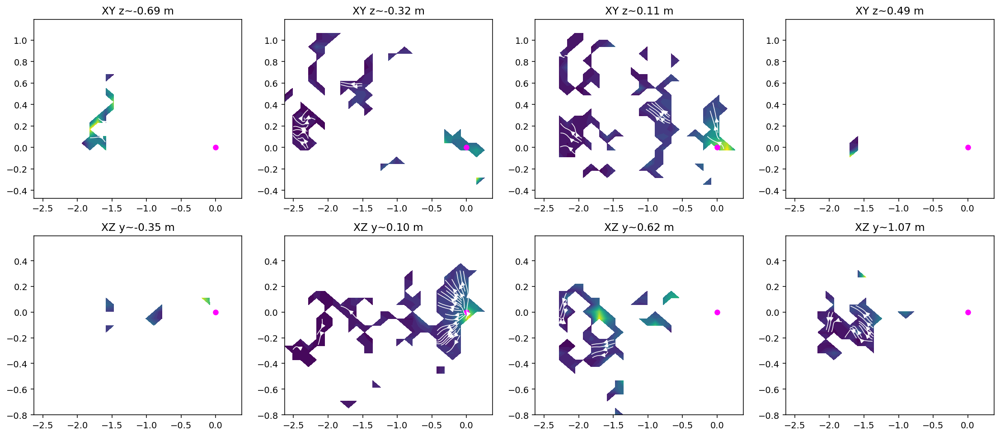

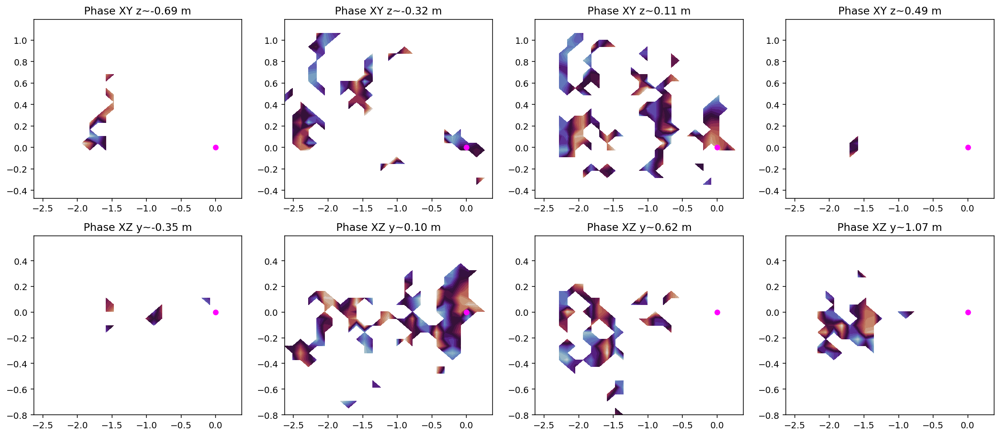

In [90]:
# quick flow + phase slices (same approach as run_flow_oriented_npz)
def voxel_average_scalar(pos, val, grid):
    gx, gy, gz = grid
    ix = np.clip(np.digitize(pos[:, 0], gx) - 1, 0, len(gx) - 2)
    iy = np.clip(np.digitize(pos[:, 1], gy) - 1, 0, len(gy) - 2)
    iz = np.clip(np.digitize(pos[:, 2], gz) - 1, 0, len(gz) - 2)
    out = np.full((len(gx)-1, len(gy)-1, len(gz)-1), np.nan)
    count = np.zeros(out.shape, dtype=int)
    for a, b, c, v in zip(ix, iy, iz, val):
        if np.isnan(out[a, b, c]):
            out[a, b, c] = v
        else:
            out[a, b, c] += v
        count[a, b, c] += 1
    out = out / np.maximum(count, 1)
    return out
def voxel_average_vec(pos, vec, grid):
    gx, gy, gz = grid
    ix = np.clip(np.digitize(pos[:, 0], gx) - 1, 0, len(gx) - 2)
    iy = np.clip(np.digitize(pos[:, 1], gy) - 1, 0, len(gy) - 2)
    iz = np.clip(np.digitize(pos[:, 2], gz) - 1, 0, len(gz) - 2)
    out = np.full((len(gx)-1, len(gy)-1, len(gz)-1, 3), np.nan)
    count = np.zeros(out.shape[:3], dtype=int)
    for a, b, c, v in zip(ix, iy, iz, vec):
        if np.isnan(out[a, b, c, 0]):
            out[a, b, c] = v
        else:
            out[a, b, c] += v
        count[a, b, c] += 1
    out = out / np.maximum(count[..., None], 1)
    return out

J = 0.5 * P[:,None] * np.conj(U)
I = np.real(J)
Pmag = np.abs(P)
Pph = np.angle(P)

# ensure streamlines point outward from the source (using strong-signal points)
rad = pos / (np.linalg.norm(pos, axis=1, keepdims=True) + 1e-12)
mask = Pmag >= np.percentile(Pmag, 75)
score = np.mean(np.sum(I[mask] * rad[mask], axis=1))
print('radial intensity score (top 25% |P|):', score)
if score < 0:
    I = -I

xmin,ymin,zmin = pos.min(0)
xmax,ymax,zmax = pos.max(0)
gx = np.linspace(xmin,xmax,28)
gy = np.linspace(ymin,ymax,28)
gz = np.linspace(zmin,zmax,28)
xc = 0.5*(gx[:-1]+gx[1:])
yc = 0.5*(gy[:-1]+gy[1:])
zc = 0.5*(gz[:-1]+gz[1:])
Igrid = voxel_average_vec(pos, I, (gx,gy,gz))
Pmag_grid = voxel_average_scalar(pos, Pmag, (gx,gy,gz))
Pph_grid = voxel_average_scalar(pos, Pph, (gx,gy,gz))

iz_list = [int(np.argmin(np.abs(zc-z))) for z in np.linspace(zc[2], zc[-3], 4)]
iy_list = [int(np.argmin(np.abs(yc-y))) for y in np.linspace(yc[2], yc[-3], 4)]

fig, axes = plt.subplots(2, 4, figsize=(16,7), dpi=140)
for i,iz in enumerate(iz_list):
    X,Y = np.meshgrid(xc,yc,indexing='xy')
    Uxy = Igrid[:,:,iz,0].T
    Vxy = Igrid[:,:,iz,1].T
    axes[0,i].contourf(X,Y,Pmag_grid[:,:,iz].T,levels=28,cmap='viridis')
    axes[0,i].streamplot(X,Y,Uxy,Vxy,density=2.5,color='w',linewidth=0.8)
    axes[0,i].scatter([0],[0],s=30,c='magenta')
    axes[0,i].set_title(f'XY z~{zc[iz]:.2f} m')
for i,iy in enumerate(iy_list):
    X,Zm = np.meshgrid(xc,zc,indexing='xy')
    Uxz = Igrid[:,iy,:,0].T
    Vxz = Igrid[:,iy,:,2].T
    axes[1,i].contourf(X,Zm,Pmag_grid[:,iy,:].T,levels=28,cmap='viridis')
    axes[1,i].streamplot(X,Zm,Uxz,Vxz,density=2.5,color='w',linewidth=0.8)
    axes[1,i].scatter([0],[0],s=30,c='magenta')
    axes[1,i].set_title(f'XZ y~{yc[iy]:.2f} m')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16,7), dpi=140)
for i,iz in enumerate(iz_list):
    X,Y = np.meshgrid(xc,yc,indexing='xy')
    axes[0,i].contourf(X,Y,Pph_grid[:,:,iz].T,levels=28,cmap='twilight')
    axes[0,i].scatter([0],[0],s=30,c='magenta')
    axes[0,i].set_title(f'Phase XY z~{zc[iz]:.2f} m')
for i,iy in enumerate(iy_list):
    X,Zm = np.meshgrid(xc,zc,indexing='xy')
    axes[1,i].contourf(X,Zm,Pph_grid[:,iy,:].T,levels=28,cmap='twilight')
    axes[1,i].scatter([0],[0],s=30,c='magenta')
    axes[1,i].set_title(f'Phase XZ y~{yc[iy]:.2f} m')
plt.tight_layout(); plt.show()


## Room-aligned hero visualization (static)


In [ ]:
# Static hero image: room mesh + active intensity vectors + pressure phase
I = np.real(0.5 * P[:, None] * np.conj(U))
Pph = np.angle(P)
Pmag = np.abs(P)

rng = np.random.default_rng(0)
mask = Pmag >= np.percentile(Pmag, 70)
idx_pool = np.where(mask)[0]
if len(idx_pool) > 1600:
    idx = rng.choice(idx_pool, 1600, replace=False)
else:
    idx = idx_pool

fig = plt.figure(figsize=(10, 7), dpi=160)
ax = fig.add_subplot(111, projection='3d')

if mesh_verts is not None and mesh_faces is not None and len(mesh_faces) > 0:
    tris = mesh_verts[mesh_faces]
    mesh_poly = Poly3DCollection(tris, facecolor=(0.75, 0.75, 0.75, 0.12), edgecolor='none')
    ax.add_collection3d(mesh_poly)

sc = ax.scatter(pos[idx,0], pos[idx,1], pos[idx,2], c=Pph[idx], s=8, cmap='twilight', alpha=0.9)
ax.quiver(pos[idx,0], pos[idx,1], pos[idx,2],
          I[idx,0], I[idx,1], I[idx,2],
          length=0.28, normalize=True, color='k', linewidth=0.5, alpha=0.55)

ax.set_title('750 Hz acoustic flow (room-aligned)')
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.set_zlabel('z [m]')

rng_box = pos.max(0) - pos.min(0)
ax.set_box_aspect((rng_box[0], rng_box[1], rng_box[2]))
ax.view_init(elev=18, azim=28)

cb = fig.colorbar(sc, ax=ax, shrink=0.65, pad=0.02)
cb.set_label('Pressure phase [rad]')

out_png = ROOT/'figs/examples/martial_measurements/martial_750Hz_room_hero.png'
fig.savefig(out_png, bbox_inches='tight')
plt.show()
print('saved', out_png)


## Room-aligned pseudo-time animation (particle velocity)


In [ ]:
import shutil
import subprocess

frames = 48
phase = np.linspace(0, 2*np.pi, frames, endpoint=False)

Pmag = np.abs(P)
mask = Pmag >= np.percentile(Pmag, 75)
idx_pool = np.where(mask)[0]
rng = np.random.default_rng(1)
if len(idx_pool) > 1400:
    idx = rng.choice(idx_pool, 1400, replace=False)
else:
    idx = idx_pool

vmax = np.percentile(np.abs(P[idx]), 95)

out_dir = ROOT/'figs/examples/martial_measurements/martial_750Hz_room_pseudotime_frames'
out_dir.mkdir(parents=True, exist_ok=True)

for i, ph in enumerate(phase):
    u_t = np.real(U * np.exp(1j * ph))
    p_t = np.real(P * np.exp(1j * ph))
    t_ms = (ph / (2*np.pi)) / f0 * 1e3

    fig = plt.figure(figsize=(10, 7), dpi=140)
    ax = fig.add_subplot(111, projection='3d')

    if mesh_verts is not None and mesh_faces is not None and len(mesh_faces) > 0:
        tris = mesh_verts[mesh_faces]
        mesh_poly = Poly3DCollection(tris, facecolor=(0.75, 0.75, 0.75, 0.10), edgecolor='none')
        ax.add_collection3d(mesh_poly)

    sc = ax.scatter(pos[idx,0], pos[idx,1], pos[idx,2], c=p_t[idx], s=6,
                    cmap='coolwarm', vmin=-vmax, vmax=vmax, alpha=0.55)
    ax.quiver(pos[idx,0], pos[idx,1], pos[idx,2],
              u_t[idx,0], u_t[idx,1], u_t[idx,2],
              length=0.25, normalize=True, color='k', linewidth=0.4, alpha=0.35)

    ax.set_title(f'750 Hz pseudo-time (t = {t_ms:.2f} ms)')
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')
    ax.set_zlabel('z [m]')
    rng_box = pos.max(0) - pos.min(0)
    ax.set_box_aspect((rng_box[0], rng_box[1], rng_box[2]))
    ax.view_init(elev=18, azim=28)

    fig.colorbar(sc, ax=ax, shrink=0.65, pad=0.02, label='Pressure [arb]')

    out = out_dir / f'frame_{i:03d}.png'
    fig.savefig(out, bbox_inches='tight')
    plt.close(fig)

mp4 = ROOT/'figs/examples/martial_measurements/martial_750Hz_room_pseudotime.mp4'
if shutil.which('ffmpeg'):
    cmd = ['ffmpeg', '-y', '-r', '24', '-i', str(out_dir/'frame_%03d.png'),
           '-c:v', 'libx264', '-pix_fmt', 'yuv420p', str(mp4)]
    subprocess.run(cmd, check=False)
    print('saved', mp4)
else:
    print('ffmpeg not found; frames saved in', out_dir)


saved /Users/marcialsanchis/Desktop/PhD/ModeAir/MicroFLown/final_pipe/figs/examples/martial_measurements/martial_750Hz_room_pseudotime.mp4


ffmpeg version 8.0 Copyright (c) 2000-2025 the FFmpeg developers
  built with Apple clang version 17.0.0 (clang-1700.0.13.3)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/8.0_1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

## SH extrapolation: near -> far (measured vs predicted)
We fit spherical harmonics using the *near* cluster (closest to the source) and compare the predicted field
against *all measured points* (the held-out cluster is used for error plots).


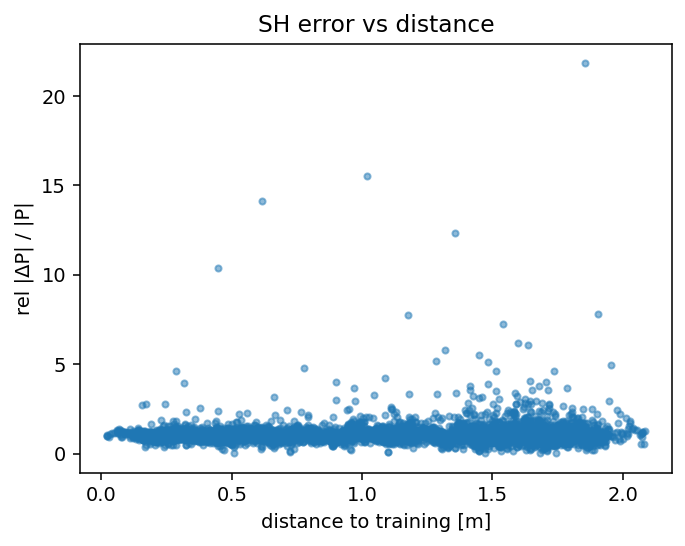

In [ ]:
import sys
from pathlib import Path
def find_root():
    p = Path.cwd()
    for _ in range(8):
        if (p/'src'/'mf_pipeline').exists() or (p/'pyproject.toml').exists():
            return p
        p = p.parent
    return Path.cwd()
ROOT = find_root()
if str(PIPE_ROOT/'src') not in sys.path:
    sys.path.insert(0, str(PIPE_ROOT/'src'))
from mf_pipeline.mf_directivity import angles_from_pos, fit_complex_SH_nearfield, SHFitOptions, eval_complex_SH_points
import sys
from pathlib import Path
ROOT = Path('.').resolve()
if str(PIPE_ROOT/'src') not in sys.path:
    sys.path.insert(0, str(PIPE_ROOT/'src'))
from mf_pipeline.mf_directivity import angles_from_pos, fit_complex_SH_nearfield, SHFitOptions, eval_complex_SH_points

def kmeans3(x, seed=0, iters=60):
    rng = np.random.default_rng(seed)
    cent = x[rng.choice(len(x), 3, replace=False)]
    for _ in range(iters):
        dist = ((x[:, None, :] - cent[None, :, :]) ** 2).sum(axis=2)
        lab = dist.argmin(axis=1)
        new_cent = np.array([x[lab == i].mean(axis=0) for i in range(3)])
        if np.allclose(new_cent, cent, atol=1e-5):
            break
        cent = new_cent
    return lab, cent

labels, cent = kmeans3(pos)
train_id = int(np.argmin(np.linalg.norm(cent - np.array([[0,0,0]]), axis=1)))
train_mask = labels == train_id
test_mask = ~train_mask

c = 343.0
k = 2.0 * np.pi * f0 / c
r, th, ph = angles_from_pos(pos[train_mask], np.zeros(3))
a = fit_complex_SH_nearfield(P[train_mask], r, th, ph, k, SHFitOptions(lmax=8, lam=1e-3))
r_all, th_all, ph_all = angles_from_pos(pos, np.zeros(3))
P_pred = eval_complex_SH_points(a, r_all, th_all, ph_all, k, 8)

# error vs distance
train_pts = pos[train_mask]
test_pts = pos[test_mask]
d2 = ((test_pts[:, None, :] - train_pts[None, :, :]) ** 2).sum(axis=2)
dmin = np.sqrt(d2.min(axis=1))
rel_err = np.abs(P_pred[test_mask] - P[test_mask]) / np.maximum(np.abs(P[test_mask]), 1e-12)

plt.figure(figsize=(5,4), dpi=140)
plt.scatter(dmin, rel_err, s=10, alpha=0.5)
plt.xlabel('distance to training [m]')
plt.ylabel('rel |ΔP| / |P|')
plt.title('SH error vs distance')
plt.tight_layout()
plt.show()


## Measured vs predicted slices


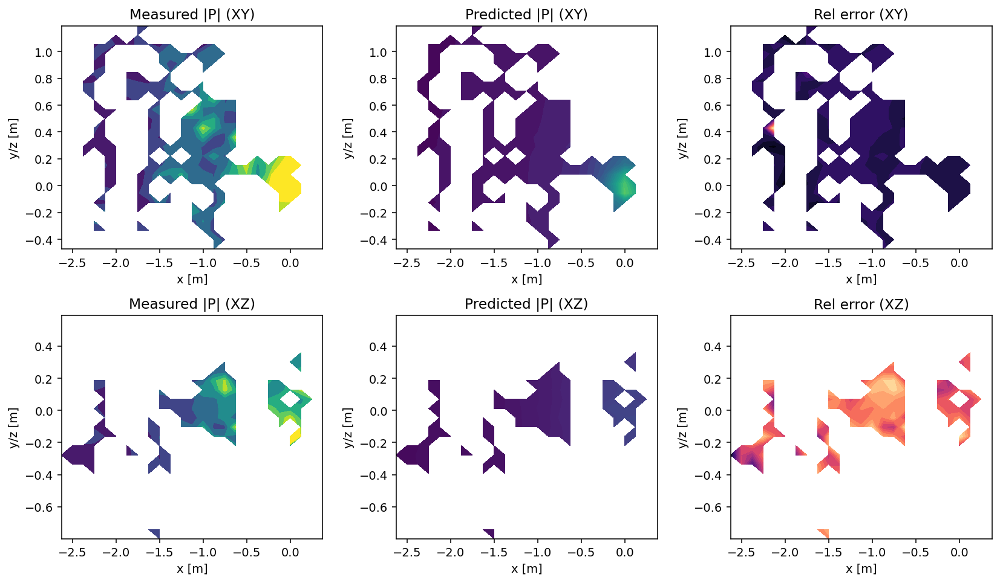

In [ ]:
def voxel_average_scalar(pos, val, grid):
    gx, gy, gz = grid
    ix = np.clip(np.digitize(pos[:, 0], gx) - 1, 0, len(gx) - 2)
    iy = np.clip(np.digitize(pos[:, 1], gy) - 1, 0, len(gy) - 2)
    iz = np.clip(np.digitize(pos[:, 2], gz) - 1, 0, len(gz) - 2)
    out = np.full((len(gx)-1, len(gy)-1, len(gz)-1), np.nan)
    count = np.zeros(out.shape, dtype=int)
    for a, b, c, v in zip(ix, iy, iz, val):
        if np.isnan(out[a, b, c]):
            out[a, b, c] = v
        else:
            out[a, b, c] += v
        count[a, b, c] += 1
    out = out / np.maximum(count, 1)
    return out

xmin, ymin, zmin = pos.min(0)
xmax, ymax, zmax = pos.max(0)
gx = np.linspace(xmin, xmax, 26)
gy = np.linspace(ymin, ymax, 26)
gz = np.linspace(zmin, zmax, 26)
xc = 0.5 * (gx[:-1] + gx[1:])
yc = 0.5 * (gy[:-1] + gy[1:])
zc = 0.5 * (gz[:-1] + gz[1:])
iz = len(zc)//2
iy = len(yc)//2

meas = voxel_average_scalar(pos, np.abs(P), (gx, gy, gz))
pred = voxel_average_scalar(pos, np.abs(P_pred), (gx, gy, gz))
err = np.abs(pred - meas) / np.maximum(meas, 1e-12)
vmax = np.nanpercentile(meas, 95)

fig, axes = plt.subplots(2, 3, figsize=(12, 7), dpi=140)
X, Y = np.meshgrid(xc, yc, indexing='xy')
Xz, Zm = np.meshgrid(xc, zc, indexing='xy')
axes[0,0].contourf(X, Y, meas[:, :, iz].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[0,0].set_title('Measured |P| (XY)')
axes[0,1].contourf(X, Y, pred[:, :, iz].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[0,1].set_title('Predicted |P| (XY)')
axes[0,2].contourf(X, Y, err[:, :, iz].T, levels=20, cmap='magma')
axes[0,2].set_title('Rel error (XY)')

axes[1,0].contourf(Xz, Zm, meas[:, iy, :].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[1,0].set_title('Measured |P| (XZ)')
axes[1,1].contourf(Xz, Zm, pred[:, iy, :].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[1,1].set_title('Predicted |P| (XZ)')
axes[1,2].contourf(Xz, Zm, err[:, iy, :].T, levels=20, cmap='magma')
axes[1,2].set_title('Rel error (XZ)')
for ax in axes.ravel():
    ax.set_xlabel('x [m]'); ax.set_ylabel('y/z [m]')
fig.tight_layout()
plt.show()


## Reversible vs irreversible energy (time domain)
Compute active (I) and reactive (Q) intensity proxies from raw time data across Measurement2..9.


Reversible ratio |Q|/|I| per measurement: [np.float32(3127724.0), np.float32(255101.61), np.float32(675371.7), np.float32(1355345.1), np.float32(928203.7), np.float32(4059943.8), np.float32(1091485.2), np.float32(545813.06)]


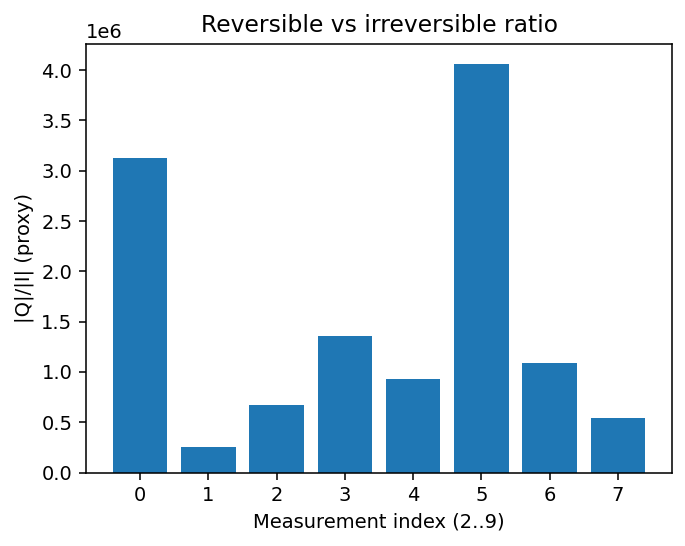

In [ ]:
from numpy.fft import rfft, rfftfreq
with h5py.File(PRJ, 'r') as f:
    meas = [k for k in f.keys() if k.startswith('Measurement')][1:]
    ratios = []
    for k in meas:
        td = f[f'{k}/TimeData'][:]
        Pch = td[4]
        Uch = td[0]
        P_fft = rfft(Pch)
        U_fft = rfft(Uch)
        fs = float(f[f'{k}/daqinfo/ObjInfo'][0]['SampleRate'])
        freqs = rfftfreq(len(Pch), d=1/fs)
        fi = int(np.argmin(np.abs(freqs - f0)))
        band_p = np.zeros_like(P_fft); band_p[fi] = P_fft[fi]
        band_u = np.zeros_like(U_fft); band_u[fi] = U_fft[fi]
        p_nb = np.fft.irfft(band_p, n=len(Pch))
        u_nb = np.fft.irfft(band_u, n=len(Uch))
        I_nb = p_nb * u_nb
        # quadrature proxy for Q
        P_an = np.fft.irfft(P_fft * (1j))
        U_an = np.fft.irfft(U_fft * (1j))
        Q_nb = P_an * U_an
        ratio = np.mean(np.abs(Q_nb)) / (np.mean(np.abs(I_nb)) + 1e-12)
        ratios.append(ratio)
    print('Reversible ratio |Q|/|I| per measurement:', ratios)
    plt.figure(figsize=(5,4), dpi=140)
    plt.bar(range(len(ratios)), ratios)
    plt.xlabel('Measurement index (2..9)')
    plt.ylabel('|Q|/|I| (proxy)')
    plt.title('Reversible vs irreversible ratio')
    plt.tight_layout()
    plt.show()


## Improved extrapolation (radial split + parameter sweep)
We split points by distance to the source (near = train, far = test), fit SH on the near points,
and evaluate predictions on far points (extrapolation beyond the training region).


train 2757 test 6433


lmax 6 lam 0.001 median err 1.0319256949439857
lmax 8 lam 0.001 median err 1.0319287487921323
lmax 10 lam 0.0005 median err 1.0319284021067963
lmax 12 lam 0.0001 median err 1.031929382519466
Best 6 0.001 median err 1.0319256949439857


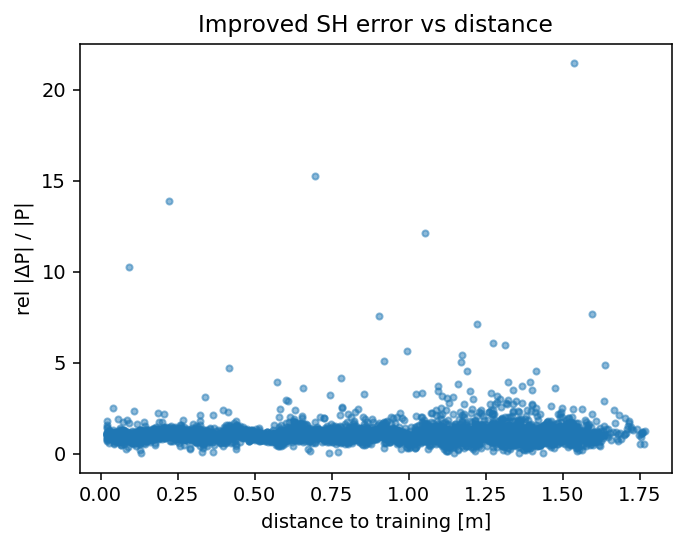

In [ ]:
from mf_pipeline.mf_directivity import angles_from_pos, fit_complex_SH_nearfield, SHFitOptions, eval_complex_SH_points
r = np.linalg.norm(pos, axis=1)
cut = np.percentile(r, 30)
train_mask = r <= cut
test_mask = r > cut
print('train', train_mask.sum(), 'test', test_mask.sum())

def eval_params(lmax, lam):
    k = 2.0 * np.pi * f0 / 343.0
    r_tr, th_tr, ph_tr = angles_from_pos(pos[train_mask], np.zeros(3))
    a = fit_complex_SH_nearfield(P[train_mask], r_tr, th_tr, ph_tr, k, SHFitOptions(lmax=lmax, lam=lam))
    r_all, th_all, ph_all = angles_from_pos(pos, np.zeros(3))
    P_pred = eval_complex_SH_points(a, r_all, th_all, ph_all, k, lmax)
    rel_err = np.abs(P_pred[test_mask] - P[test_mask]) / np.maximum(np.abs(P[test_mask]), 1e-12)
    rel_err = rel_err[np.isfinite(rel_err)]
    return np.median(rel_err), P_pred

cands = [(6,1e-3),(8,1e-3),(10,5e-4),(12,1e-4)]
best = None
for lmax, lam in cands:
    med, P_pred = eval_params(lmax, lam)
    print('lmax', lmax, 'lam', lam, 'median err', med)
    if best is None or med < best[0]:
        best = (med, lmax, lam, P_pred)

med, lmax, lam, P_pred = best
print('Best', lmax, lam, 'median err', med)
train_pts = pos[train_mask]
test_pts = pos[test_mask]
d2 = ((test_pts[:, None, :] - train_pts[None, :, :]) ** 2).sum(axis=2)
dmin = np.sqrt(d2.min(axis=1))
rel_err = np.abs(P_pred[test_mask] - P[test_mask]) / np.maximum(np.abs(P[test_mask]), 1e-12)
rel_err = rel_err[np.isfinite(rel_err)]
plt.figure(figsize=(5,4), dpi=140)
plt.scatter(dmin, rel_err, s=10, alpha=0.5)
plt.xlabel('distance to training [m]')
plt.ylabel('rel |ΔP| / |P|')
plt.title('Improved SH error vs distance')
plt.tight_layout()
plt.show()


### Improved extrapolation slices (measured vs predicted)
We use a fixed (lmax, lam) to visualize the prediction on mid‑plane slices.


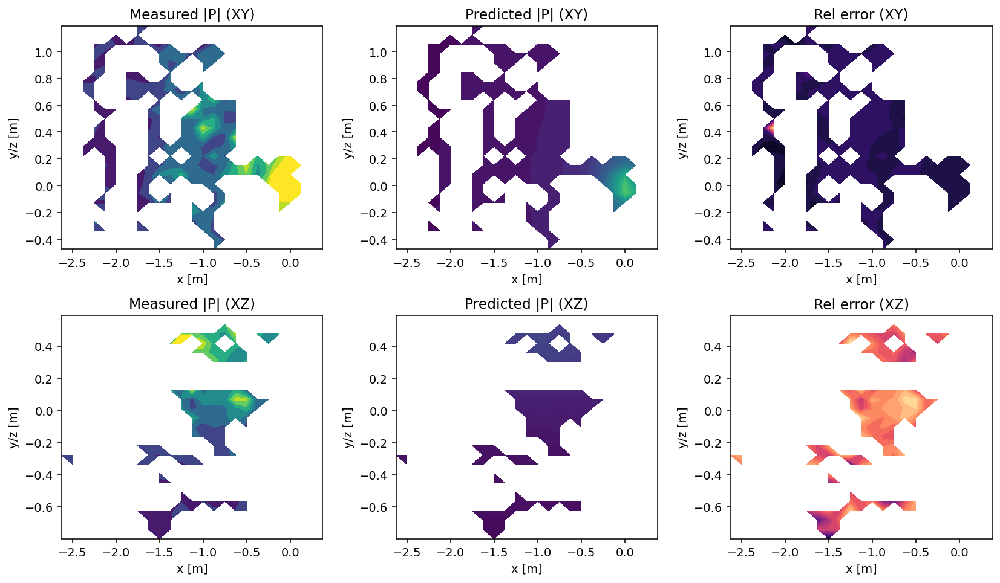

In [ ]:
# choose a representative SH setting and visualize slices
lmax = 8
lam = 1e-3
k = 2.0 * np.pi * f0 / 343.0
r_all, th_all, ph_all = angles_from_pos(pos, np.zeros(3))
r_tr, th_tr, ph_tr = angles_from_pos(pos[train_mask], np.zeros(3))
a = fit_complex_SH_nearfield(P[train_mask], r_tr, th_tr, ph_tr, k, SHFitOptions(lmax=lmax, lam=lam))
P_pred = eval_complex_SH_points(a, r_all, th_all, ph_all, k, lmax)

xmin,ymin,zmin = pos.min(0)
xmax,ymax,zmax = pos.max(0)
gx = np.linspace(xmin,xmax,26)
gy = np.linspace(ymin,ymax,26)
gz = np.linspace(zmin,zmax,26)
xc = 0.5*(gx[:-1]+gx[1:])
yc = 0.5*(gy[:-1]+gy[1:])
zc = 0.5*(gz[:-1]+gz[1:])
iz = len(zc)//2
iy = len(yc)//2

meas = voxel_average_scalar(pos, np.abs(P), (gx,gy,gz))
pred = voxel_average_scalar(pos, np.abs(P_pred), (gx,gy,gz))
err = np.abs(pred - meas) / np.maximum(meas, 1e-12)
vmax = np.nanpercentile(meas, 95)

fig, axes = plt.subplots(2, 3, figsize=(12, 7), dpi=140)
X, Y = np.meshgrid(xc, yc, indexing='xy')
Zm, Xz = np.meshgrid(zc, xc, indexing='xy')
axes[0,0].contourf(X, Y, meas[:, :, iz].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[0,0].set_title('Measured |P| (XY)')
axes[0,1].contourf(X, Y, pred[:, :, iz].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[0,1].set_title('Predicted |P| (XY)')
axes[0,2].contourf(X, Y, err[:, :, iz].T, levels=20, cmap='magma')
axes[0,2].set_title('Rel error (XY)')

axes[1,0].contourf(Xz, Zm, meas[:, iy, :].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[1,0].set_title('Measured |P| (XZ)')
axes[1,1].contourf(Xz, Zm, pred[:, iy, :].T, levels=20, cmap='viridis', vmin=0, vmax=vmax)
axes[1,1].set_title('Predicted |P| (XZ)')
axes[1,2].contourf(Xz, Zm, err[:, iy, :].T, levels=20, cmap='magma')
axes[1,2].set_title('Rel error (XZ)')
for ax in axes.ravel():
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y/z [m]')
plt.tight_layout(); plt.show()


## Green's-function extrapolation (near -> far)
We estimate equivalent source strengths from *near* points (training set) and predict the field
at *far* points (test set). The comparison is between predicted far-field pressures and
measured far-field pressures at the same coordinates.
Note: this section uses only frequency-domain PSD data at 750 Hz; no time-domain signals are used.


Green extrap median err 1.0004586603781689


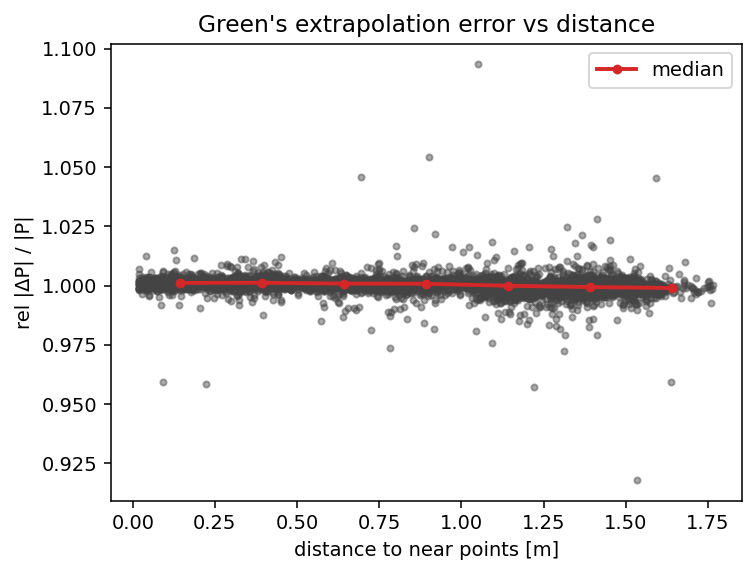

In [ ]:
# Free-space Green's function extrapolation
c = 343.0
k = 2.0 * np.pi * f0 / c
# split by radius (near/far)
r = np.linalg.norm(pos, axis=1)
cut = np.percentile(r, 30)
near_mask = r <= cut
far_mask = r > cut

pos_near = pos[near_mask]
pos_far = pos[far_mask]
p_near = P[near_mask]
p_far = P[far_mask]

def greens_matrix(src, rec, k):
    # G_ij = exp(-ik r)/ (4 pi r)
    r = np.linalg.norm(rec[:,None,:] - src[None,:,:], axis=2)
    r = np.maximum(r, 1e-6)
    return np.exp(-1j*k*r) / (4*np.pi*r)

G_nn = greens_matrix(pos_near, pos_near, k)
G_fn = greens_matrix(pos_near, pos_far, k)
# Tikhonov inversion for source strengths
lam = 1e-3
q = np.linalg.solve(G_nn.conj().T @ G_nn + lam*np.eye(G_nn.shape[1]), G_nn.conj().T @ p_near)
p_pred_far = G_fn @ q

rel_err = np.abs(p_pred_far - p_far) / np.maximum(np.abs(p_far), 1e-12)
rel_err = rel_err[np.isfinite(rel_err)]
print('Green extrap median err', np.median(rel_err))

# Error vs distance to near set
d2 = ((pos_far[:,None,:] - pos_near[None,:,:])**2).sum(axis=2)
dmin = np.sqrt(d2.min(axis=1))
fig, ax = plt.subplots(1, 1, figsize=(5.5, 4.2), dpi=140)
ax.scatter(dmin, rel_err, s=10, alpha=0.45, color='#444444')
bins = np.linspace(dmin.min(), dmin.max(), 8)
bin_cent = 0.5 * (bins[:-1] + bins[1:])
med = []
for i in range(len(bins)-1):
    m = (dmin >= bins[i]) & (dmin < bins[i+1])
    med.append(np.median(rel_err[m]) if np.any(m) else np.nan)
ax.plot(bin_cent, med, '-o', color='#d62728', lw=2, ms=4, label='median')
ax.set_xlabel('distance to near points [m]')
ax.set_ylabel('rel |ΔP| / |P|')
ax.set_title("Green's extrapolation error vs distance")
ax.legend(loc='best')
plt.tight_layout(); plt.show()


### Error comparison: SH vs Green's-function (far points)
We compare relative error on the same far-point set used for Green's-function prediction.


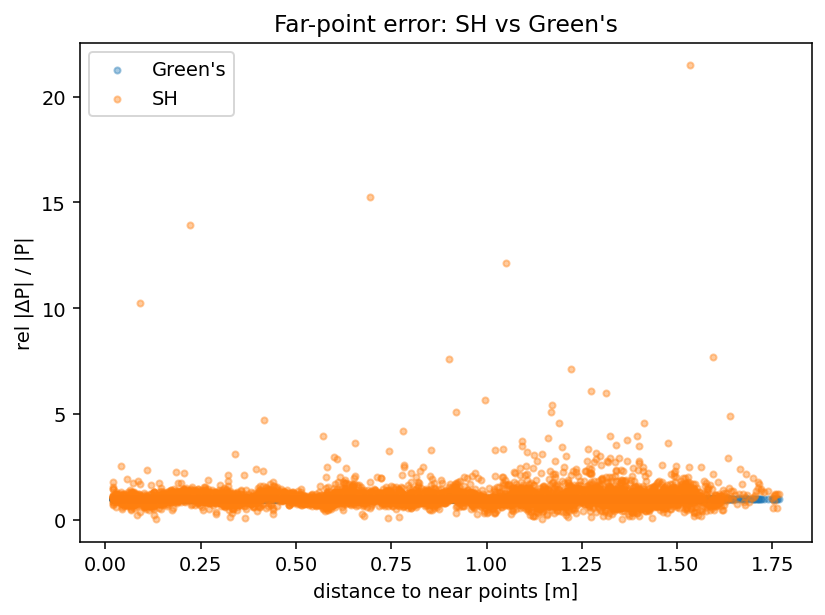

In [ ]:
# Compare SH vs Green's-function error on far points
k = 2.0 * np.pi * f0 / 343.0
# SH fit on near points
r_tr, th_tr, ph_tr = angles_from_pos(pos_near, np.zeros(3))
a_sh = fit_complex_SH_nearfield(p_near, r_tr, th_tr, ph_tr, k, SHFitOptions(lmax=8, lam=1e-3))
r_far, th_far, ph_far = angles_from_pos(pos_far, np.zeros(3))
p_pred_far_sh = eval_complex_SH_points(a_sh, r_far, th_far, ph_far, k, 8)

# Green's prediction already computed as p_pred_far
err_sh = np.abs(p_pred_far_sh - p_far) / np.maximum(np.abs(p_far), 1e-12)
err_gr = np.abs(p_pred_far - p_far) / np.maximum(np.abs(p_far), 1e-12)

# Distance to nearest near-point (same for both)
d2 = ((pos_far[:, None, :] - pos_near[None, :, :]) ** 2).sum(axis=2)
dmin = np.sqrt(d2.min(axis=1))

fig, ax = plt.subplots(1, 1, figsize=(6, 4.5), dpi=140)
ax.scatter(dmin, err_gr, s=10, alpha=0.4, label="Green's")
ax.scatter(dmin, err_sh, s=10, alpha=0.4, label='SH')
ax.set_xlabel('distance to near points [m]')
ax.set_ylabel('rel |ΔP| / |P|')
ax.set_title("Far-point error: SH vs Green's")
ax.legend(loc='best')
plt.tight_layout(); plt.show()


## Full-space Green's interpolation gallery (all data)
We use an equivalent‑source Green's model fit to *all measured points* at 750 Hz,
then predict a dense 3D grid to render smooth |P| and phase slices.
(We use a source subset for numerical stability, but all measured points are used in the fit.)


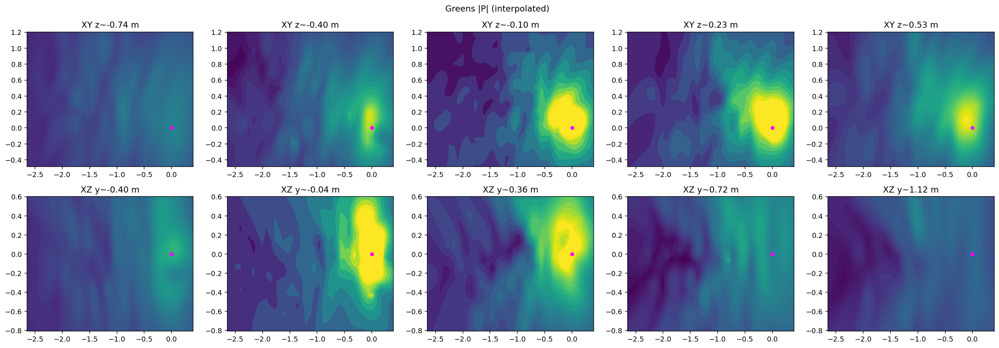

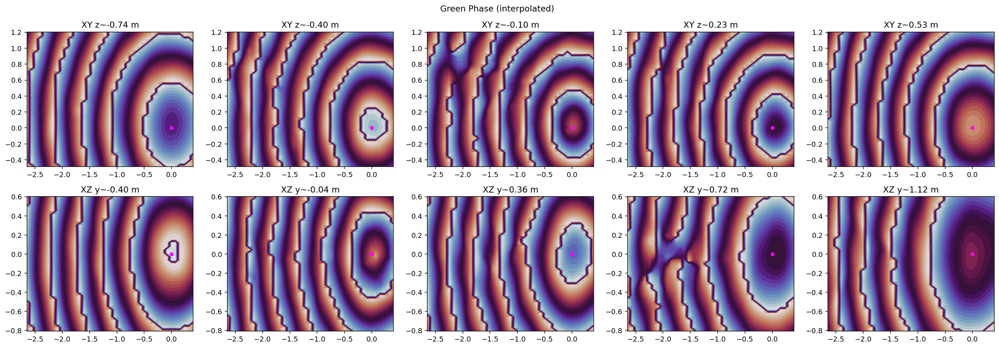

In [ ]:
# Fit equivalent sources to all measured points, then evaluate on a dense grid
c = 343.0
k = 2.0 * np.pi * f0 / c

def greens_matrix(src, rec, k):
    r = np.linalg.norm(rec[:,None,:] - src[None,:,:], axis=2)
    r = np.maximum(r, 1e-6)
    return np.exp(-1j*k*r) / (4*np.pi*r)

# choose equivalent source locations (subset of measured points)
rng = np.random.default_rng(0)
n_src = 1200 if len(pos) > 1200 else len(pos)
src_idx = rng.choice(len(pos), n_src, replace=False)
pos_src = pos[src_idx]

G_ms = greens_matrix(pos_src, pos, k)
lam = 1e-3
q = np.linalg.solve(G_ms.conj().T @ G_ms + lam*np.eye(G_ms.shape[1]), G_ms.conj().T @ P)

# dense grid prediction (chunked to save memory)
grid_n = 40
xmin,ymin,zmin = pos.min(0)
xmax,ymax,zmax = pos.max(0)
gx = np.linspace(xmin,xmax,grid_n)
gy = np.linspace(ymin,ymax,grid_n)
gz = np.linspace(zmin,zmax,grid_n)
xc = 0.5*(gx[:-1]+gx[1:])
yc = 0.5*(gy[:-1]+gy[1:])
zc = 0.5*(gz[:-1]+gz[1:])

Xg, Yg, Zg = np.meshgrid(xc, yc, zc, indexing='xy')
pos_grid = np.column_stack([Xg.ravel(), Yg.ravel(), Zg.ravel()])

def predict_grid(pos_grid, pos_src, q, k, chunk=2000):
    out = np.zeros(len(pos_grid), dtype=complex)
    for i in range(0, len(pos_grid), chunk):
        rec = pos_grid[i:i+chunk]
        G = greens_matrix(pos_src, rec, k)
        out[i:i+chunk] = G @ q
    return out

P_grid = predict_grid(pos_grid, pos_src, q, k, chunk=2000)
Pmag_grid = np.abs(P_grid).reshape(len(yc), len(xc), len(zc)).transpose(1,0,2)
Pph_grid = np.angle(P_grid).reshape(len(yc), len(xc), len(zc)).transpose(1,0,2)

# gallery slices
iz_list = [int(np.argmin(np.abs(zc-z))) for z in np.linspace(zc[2], zc[-3], 5)]
iy_list = [int(np.argmin(np.abs(yc-y))) for y in np.linspace(yc[2], yc[-3], 5)]

def gallery_field(field, title, cmap, vmin=None, vmax=None):
    fig, axes = plt.subplots(2, len(iz_list), figsize=(4*len(iz_list), 7), dpi=140)
    for i,iz in enumerate(iz_list):
        X,Y = np.meshgrid(xc,yc,indexing='xy')
        axes[0,i].contourf(X,Y,field[:,:,iz].T,levels=28,cmap=cmap,vmin=vmin,vmax=vmax)
        axes[0,i].scatter([0],[0],s=20,c='magenta')
        axes[0,i].set_title(f'XY z~{zc[iz]:.2f} m')
    for i,iy in enumerate(iy_list):
        X,Zm = np.meshgrid(xc,zc,indexing='xy')
        axes[1,i].contourf(X,Zm,field[:,iy,:].T,levels=28,cmap=cmap,vmin=vmin,vmax=vmax)
        axes[1,i].scatter([0],[0],s=20,c='magenta')
        axes[1,i].set_title(f'XZ y~{yc[iy]:.2f} m')
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

vmax = np.nanpercentile(Pmag_grid, 98)
gallery_field(Pmag_grid, 'Greens |P| (interpolated)', 'viridis', vmin=0, vmax=vmax)
gallery_field(Pph_grid, 'Green Phase (interpolated)', 'twilight', vmin=-np.pi, vmax=np.pi)


## Multi-frequency gallery with Green's interpolation + flow streamlines
We loop over the available oriented frequencies, fit Green's equivalent sources for P,
interpolate the active intensity field for streamlines, and render room‑aligned slices + 3D views.


frequencies: ['oriented_1008Hz', 'oriented_1242Hz', 'oriented_258Hz', 'oriented_492Hz', 'oriented_750Hz']


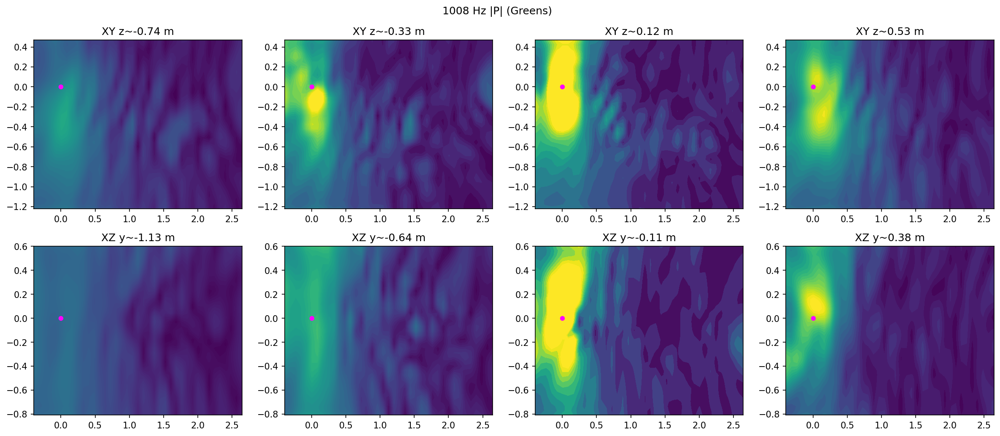

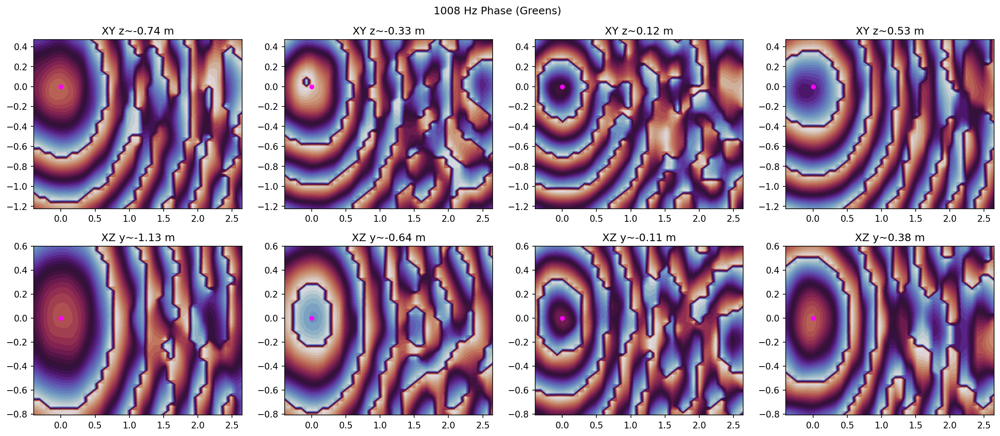

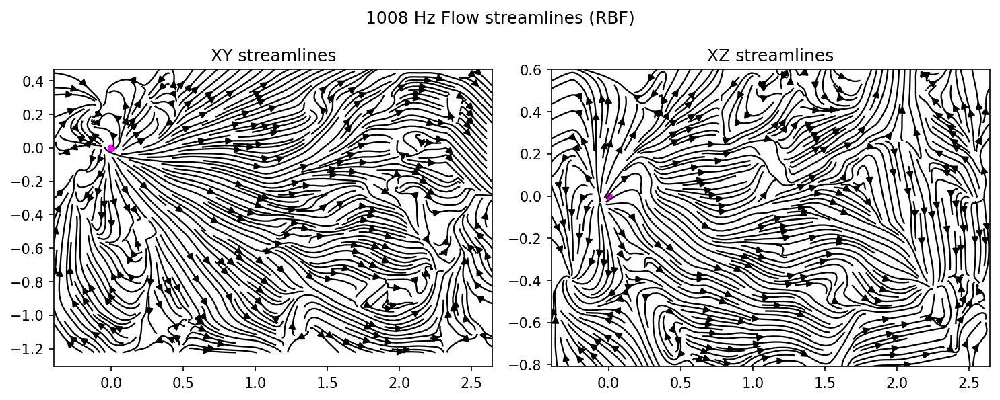

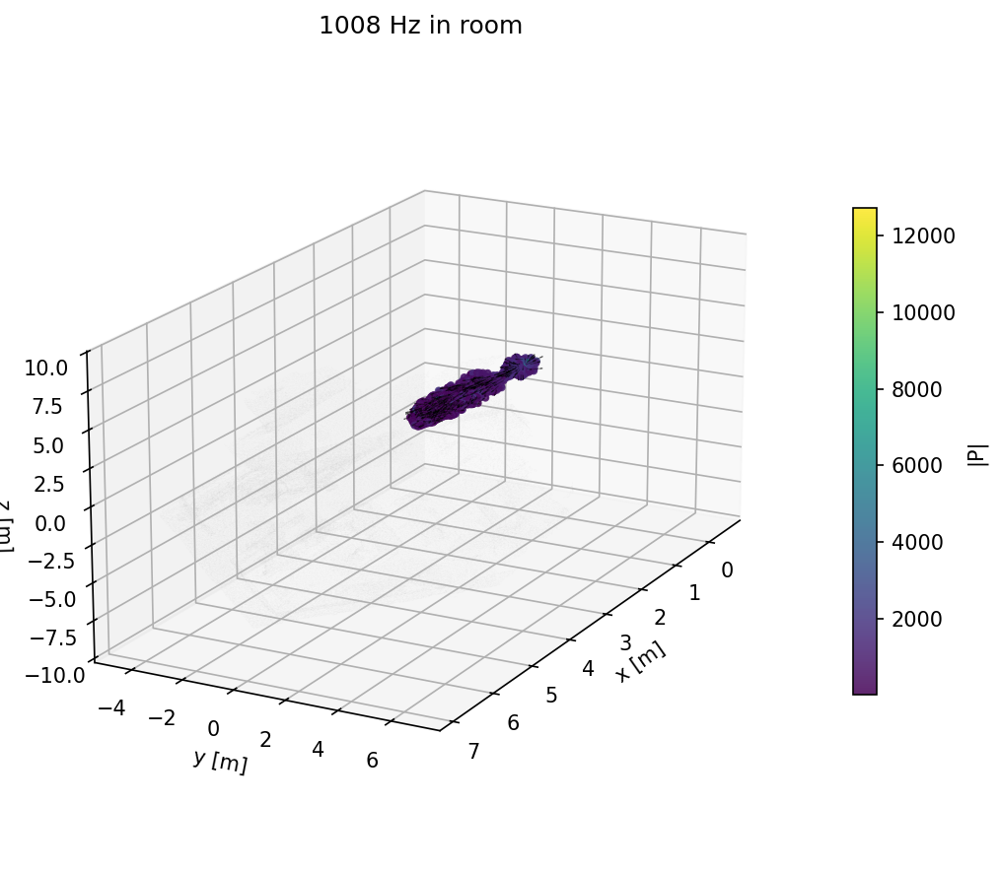

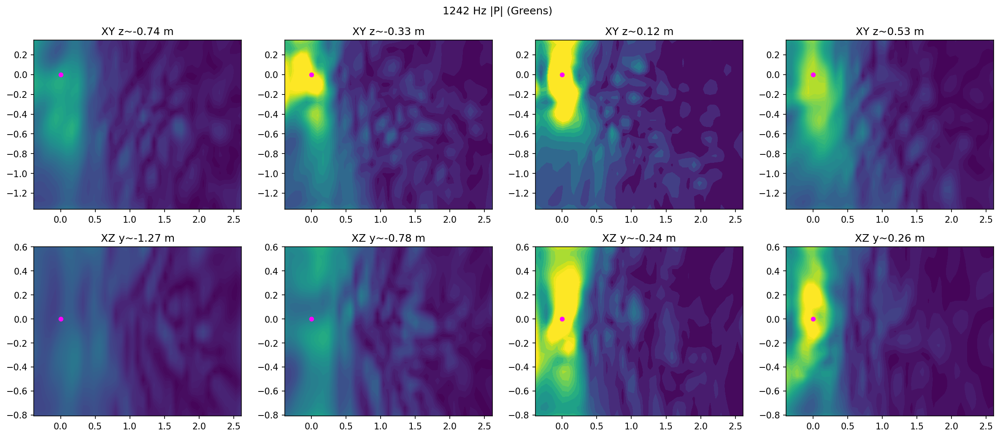

...

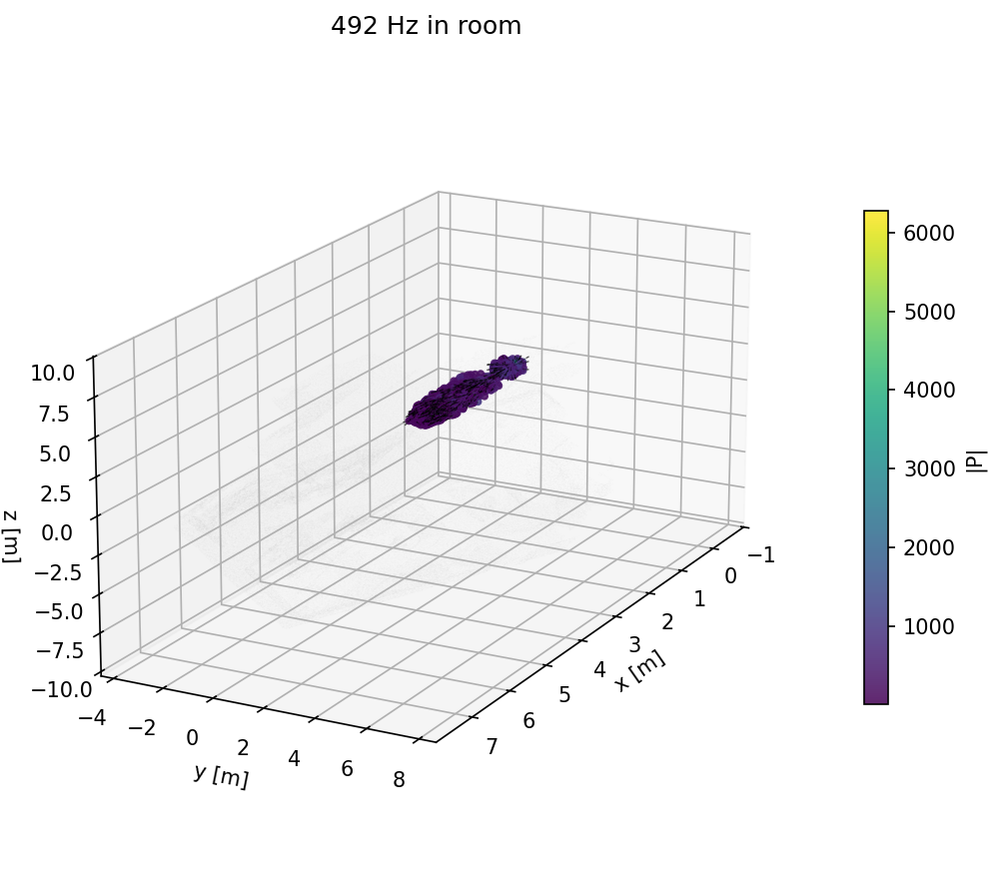

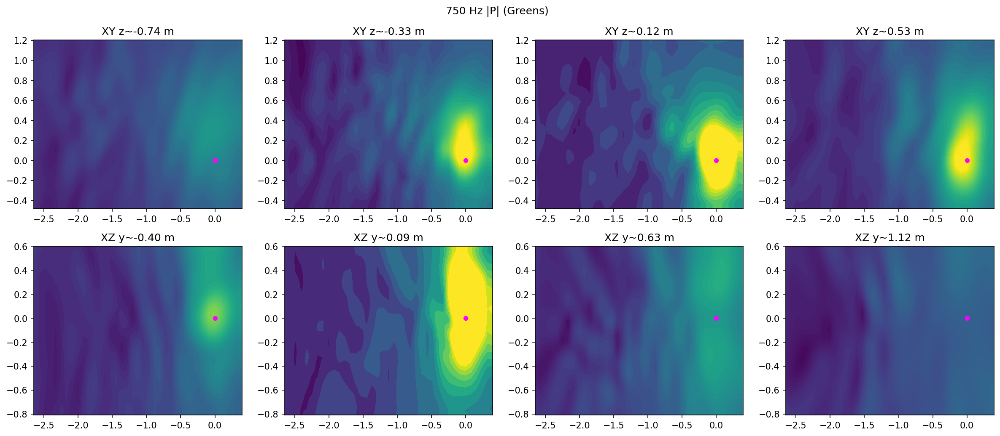

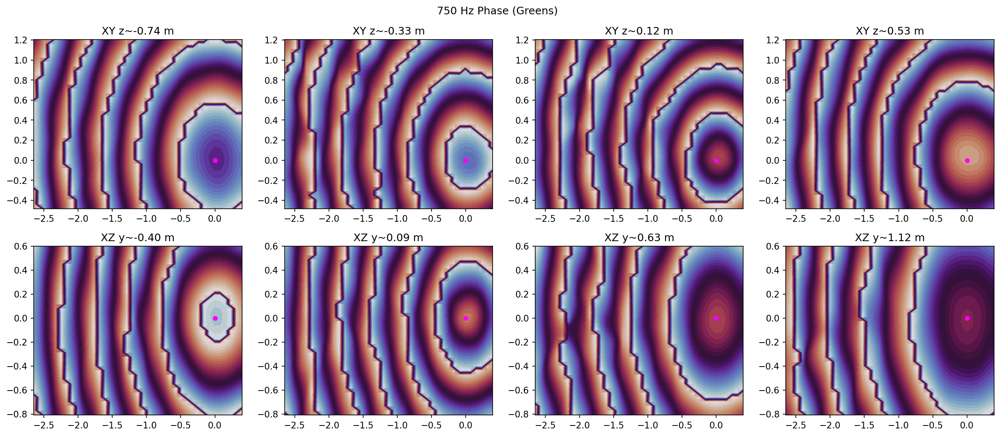

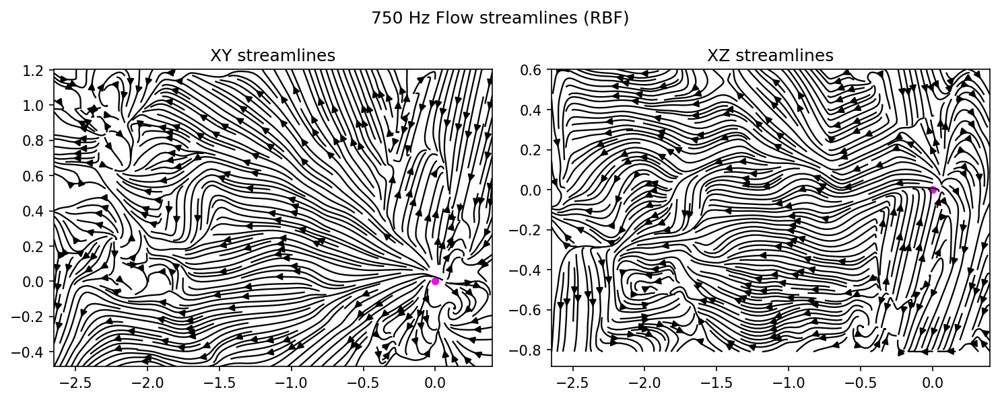

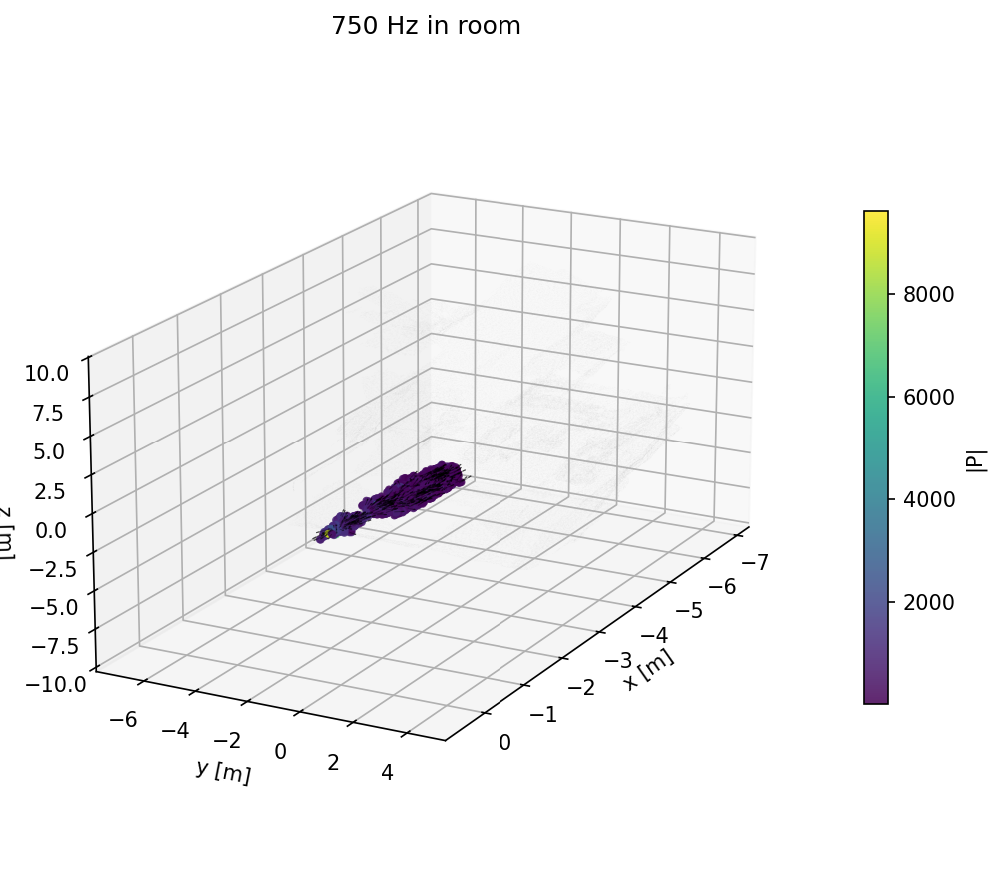

In [ ]:
from scipy.interpolate import RBFInterpolator
from scipy.ndimage import gaussian_filter

ORIENTED_DIR = ROOT/'experiment'/'data'/'martial'/'oriented'
if not ORIENTED_DIR.exists():
    ORIENTED_DIR = Path('/Users/marcialsanchis/Desktop/PhD/ModeAir/MicroFLown/final_pipe/figs/examples/martial_measurements')
freq_folders = sorted([p for p in ORIENTED_DIR.glob('oriented_*Hz') if p.is_dir()])
print('frequencies:', [p.name for p in freq_folders])

def load_oriented_npz(folder):
    npz = next(folder.glob('martial_oriented_*Hz.npz'))
    Z = np.load(npz, allow_pickle=True)
    return Z

def load_room_mesh(center, R_floor, R_int):
    mesh_path = ROOT/'figs/examples/martial_measurements/textured_output.obj'
    if not mesh_path.exists():
        mesh_path = ROOM_OBJ
    if not mesh_path.exists():
        return None, None
    verts, faces = [], []
    with open(mesh_path, 'r') as fh:
        for line in fh:
            if line.startswith('v '):
                _, x, y, z = line.strip().split()[:4]
                verts.append([float(x), float(y), float(z)])
            elif line.startswith('f '):
                toks = line.strip().split()[1:]
                idx = []
                for t in toks:
                    t = t.split('/')[0]
                    if t:
                        idx.append(int(t) - 1)
                if len(idx) >= 3:
                    for k in range(1, len(idx) - 1):
                        faces.append([idx[0], idx[k], idx[k + 1]])
    verts = (np.asarray(verts) - center[None, :]) @ R_floor.T
    verts = verts @ R_int.T
    faces = np.asarray(faces)
    if faces.shape[0] > 120000:
        step = max(1, faces.shape[0] // 120000)
        faces = faces[::step]
    return verts, faces

def greens_matrix(src, rec, k):
    r = np.linalg.norm(rec[:,None,:] - src[None,:,:], axis=2)
    r = np.maximum(r, 1e-6)
    return np.exp(-1j*k*r) / (4*np.pi*r)

def predict_green_grid(pos, P, f0, grid_n=40, n_src=1000, lam=1e-3):
    k = 2.0 * np.pi * f0 / 343.0
    rng = np.random.default_rng(0)
    n_src = min(n_src, len(pos))
    src_idx = rng.choice(len(pos), n_src, replace=False)
    pos_src = pos[src_idx]
    G_ms = greens_matrix(pos_src, pos, k)
    q = np.linalg.solve(G_ms.conj().T @ G_ms + lam*np.eye(G_ms.shape[1]), G_ms.conj().T @ P)

    xmin,ymin,zmin = pos.min(0)
    xmax,ymax,zmax = pos.max(0)
    gx = np.linspace(xmin,xmax,grid_n)
    gy = np.linspace(ymin,ymax,grid_n)
    gz = np.linspace(zmin,zmax,grid_n)
    xc = 0.5*(gx[:-1]+gx[1:])
    yc = 0.5*(gy[:-1]+gy[1:])
    zc = 0.5*(gz[:-1]+gz[1:])
    Xg, Yg, Zg = np.meshgrid(xc, yc, zc, indexing='xy')
    pos_grid = np.column_stack([Xg.ravel(), Yg.ravel(), Zg.ravel()])

    def predict_chunked(pos_grid, pos_src, q, k, chunk=2000):
        out = np.zeros(len(pos_grid), dtype=complex)
        for i in range(0, len(pos_grid), chunk):
            rec = pos_grid[i:i+chunk]
            G = greens_matrix(pos_src, rec, k)
            out[i:i+chunk] = G @ q
        return out

    P_grid = predict_chunked(pos_grid, pos_src, q, k, chunk=2000)
    Pgrid = P_grid.reshape(len(yc), len(xc), len(zc)).transpose(1,0,2)
    return (xc, yc, zc), Pgrid

def smooth_complex_grid(Pgrid, sigma=1.0):
    real = gaussian_filter(Pgrid.real, sigma=sigma)
    imag = gaussian_filter(Pgrid.imag, sigma=sigma)
    return real + 1j*imag

def interpolate_I_grid(pos, I, xc, yc, zc, neighbors=120, smoothing=0.2):
    Xg, Yg, Zg = np.meshgrid(xc, yc, zc, indexing='xy')
    pos_grid = np.column_stack([Xg.ravel(), Yg.ravel(), Zg.ravel()])
    Igrid = np.zeros((len(pos_grid), 3), dtype=float)
    for j in range(3):
        rbf = RBFInterpolator(pos, I[:, j], neighbors=neighbors, smoothing=smoothing)
        Igrid[:, j] = rbf(pos_grid)
    Igrid = Igrid.reshape(len(yc), len(xc), len(zc), 3).transpose(1,0,2,3)
    return Igrid

def gallery_field(xc, yc, zc, field, title, cmap, vmin=None, vmax=None):
    iz_list = [int(np.argmin(np.abs(zc-z))) for z in np.linspace(zc[2], zc[-3], 4)]
    iy_list = [int(np.argmin(np.abs(yc-y))) for y in np.linspace(yc[2], yc[-3], 4)]
    fig, axes = plt.subplots(2, len(iz_list), figsize=(4*len(iz_list), 7), dpi=150)
    for i,iz in enumerate(iz_list):
        X,Y = np.meshgrid(xc,yc,indexing='xy')
        axes[0,i].contourf(X,Y,field[:,:,iz].T,levels=40,cmap=cmap,vmin=vmin,vmax=vmax)
        axes[0,i].scatter([0],[0],s=20,c='magenta')
        axes[0,i].set_title(f'XY z~{zc[iz]:.2f} m')
    for i,iy in enumerate(iy_list):
        X,Zm = np.meshgrid(xc,zc,indexing='xy')
        axes[1,i].contourf(X,Zm,field[:,iy,:].T,levels=40,cmap=cmap,vmin=vmin,vmax=vmax)
        axes[1,i].scatter([0],[0],s=20,c='magenta')
        axes[1,i].set_title(f'XZ y~{yc[iy]:.2f} m')
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

def gallery_streamlines(xc, yc, zc, Igrid, title):
    iz = len(zc)//2
    iy = len(yc)//2
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=150)
    X,Y = np.meshgrid(xc, yc, indexing='xy')
    Uxy = Igrid[:,:,iz,0].T
    Vxy = Igrid[:,:,iz,1].T
    axes[0].streamplot(X, Y, Uxy, Vxy, density=2.6, color='k', linewidth=1.1)
    axes[0].scatter([0],[0],s=20,c='magenta')
    axes[0].set_title('XY streamlines')
    X,Zm = np.meshgrid(xc, zc, indexing='xy')
    Uxz = Igrid[:,iy,:,0].T
    Vxz = Igrid[:,iy,:,2].T
    axes[1].streamplot(X, Zm, Uxz, Vxz, density=2.6, color='k', linewidth=1.1)
    axes[1].scatter([0],[0],s=20,c='magenta')
    axes[1].set_title('XZ streamlines')
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

def room_plot(pos, Pmag, I, mesh_verts, mesh_faces, title):
    fig = plt.figure(figsize=(9, 6), dpi=150)
    ax = fig.add_subplot(111, projection='3d')
    if mesh_verts is not None and mesh_faces is not None and len(mesh_faces) > 0:
        tris = mesh_verts[mesh_faces]
        mesh_poly = Poly3DCollection(tris, facecolor=(0.75,0.75,0.75,0.10), edgecolor='none')
        ax.add_collection3d(mesh_poly)
    idx = np.linspace(0, len(pos)-1, min(1800, len(pos))).astype(int)
    sc = ax.scatter(pos[idx,0], pos[idx,1], pos[idx,2], c=Pmag[idx], s=8, cmap='viridis', alpha=0.85)
    qidx = idx[::6]
    ax.quiver(pos[qidx,0], pos[qidx,1], pos[qidx,2],
              I[qidx,0], I[qidx,1], I[qidx,2],
              length=0.25, normalize=True, color='k', alpha=0.35, linewidth=0.5)
    ax.scatter([0],[0],[0],s=40,c='magenta')
    ax.set_title(title)
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_zlabel('z [m]')
    fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02, label='|P|')
    rng = pos.max(0) - pos.min(0)
    ax.set_box_aspect((rng[0], rng[1], rng[2]))
    ax.view_init(elev=18, azim=28)
    plt.tight_layout(); plt.show()

results = []
for folder in freq_folders:
    Z = load_oriented_npz(folder)
    pos = Z['pos']
    P = Z['P']
    U = Z['U']
    f0 = float(Z['f0'])
    center = np.asarray(Z['center'], dtype=float)
    R_floor = np.asarray(Z['R_floor'], dtype=float)
    R_int = np.asarray(Z['R_int'], dtype=float)

    # active intensity at measured points
    I = np.real(0.5 * P[:,None] * np.conj(U))
    rad = pos / (np.linalg.norm(pos, axis=1, keepdims=True) + 1e-12)
    mask = np.abs(P) >= np.percentile(np.abs(P), 75)
    if np.mean(np.sum(I[mask] * rad[mask], axis=1)) < 0:
        I = -I

    # Green's interpolation for pressure fields
    (xc, yc, zc), Pgrid = predict_green_grid(pos, P, f0, grid_n=40, n_src=1000, lam=1e-3)
    Pgrid = smooth_complex_grid(Pgrid, sigma=1.0)
    Pmag_grid = np.abs(Pgrid)
    Pph_grid = np.angle(Pgrid)

    # RBF-interpolated intensity field for streamlines
    Igrid = interpolate_I_grid(pos, I, xc, yc, zc, neighbors=140, smoothing=0.3)

    # galleries
    vmax = np.nanpercentile(Pmag_grid, 98)
    gallery_field(xc, yc, zc, Pmag_grid, f'{f0:.0f} Hz |P| (Greens)', 'viridis', vmin=0, vmax=vmax)
    gallery_field(xc, yc, zc, Pph_grid, f'{f0:.0f} Hz Phase (Greens)', 'twilight', vmin=-np.pi, vmax=np.pi)
    gallery_streamlines(xc, yc, zc, Igrid, f'{f0:.0f} Hz Flow streamlines (RBF)')

    # room plot
    mesh_verts, mesh_faces = load_room_mesh(center, R_floor, R_int)
    room_plot(pos, np.abs(P), I, mesh_verts, mesh_faces, f'{f0:.0f} Hz in room')

    results.append(dict(f0=f0, xc=xc, yc=yc, zc=zc, Pgrid=Pgrid, Igrid=Igrid))


### Combined-frequency overview
We combine all Green's-interpolated grids by averaging |P| and show a composite phase map
(phase from the frequency with max |P| at each voxel).


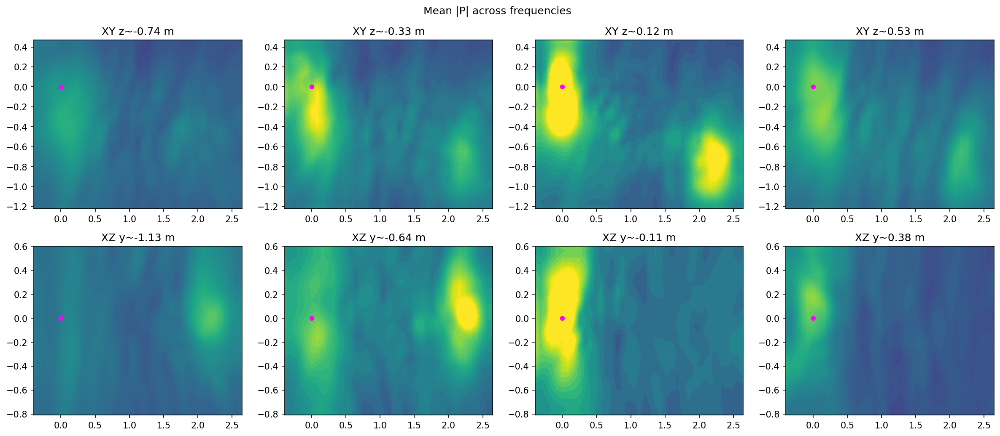

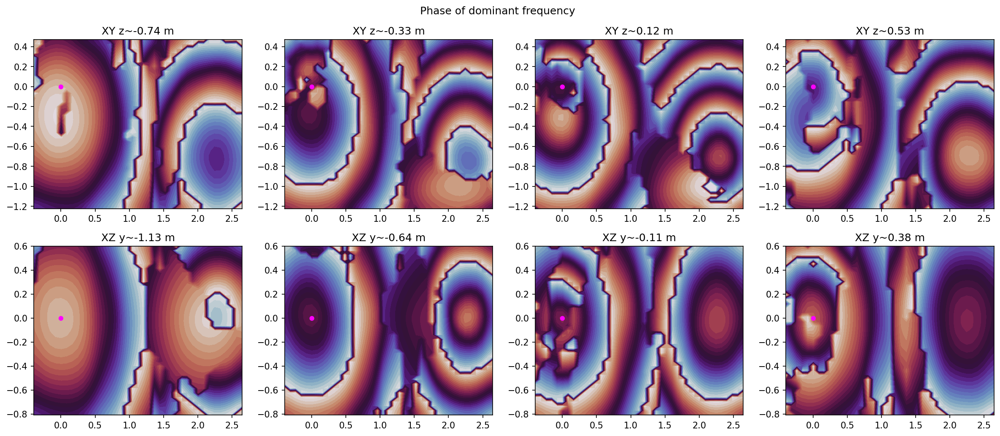

In [ ]:
# Combine across frequencies on the shared grid
if results:
    base = results[0]
    xc, yc, zc = base['xc'], base['yc'], base['zc']
    Pstack = np.stack([r['Pgrid'] for r in results], axis=0)
    Pmag = np.abs(Pstack)
    Pmag_mean = Pmag.mean(axis=0)
    idx = np.argmax(Pmag, axis=0)
    Pph_mix = np.angle(np.take_along_axis(Pstack, idx[None, ...], axis=0)[0])

    vmax = np.nanpercentile(Pmag_mean, 98)
    gallery_field(xc, yc, zc, Pmag_mean, 'Mean |P| across frequencies', 'viridis', vmin=0, vmax=vmax)
    gallery_field(xc, yc, zc, Pph_mix, 'Phase of dominant frequency', 'twilight', vmin=-np.pi, vmax=np.pi)
else:
    print('No results to combine')


## Flow shape + directivity + vortices (interpretable dynamics)
We summarize dynamics with radial profiles, polar directivity, and a vortex proxy (curl of intensity)
inside the room coordinates.


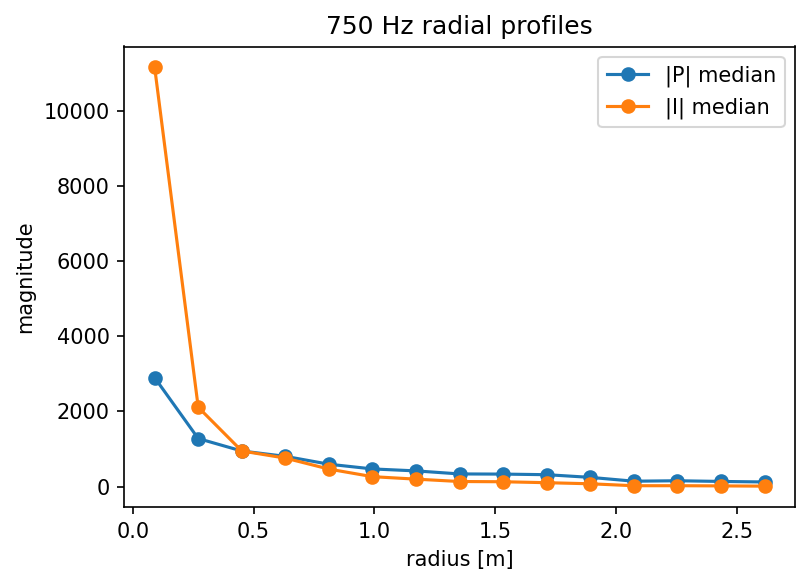

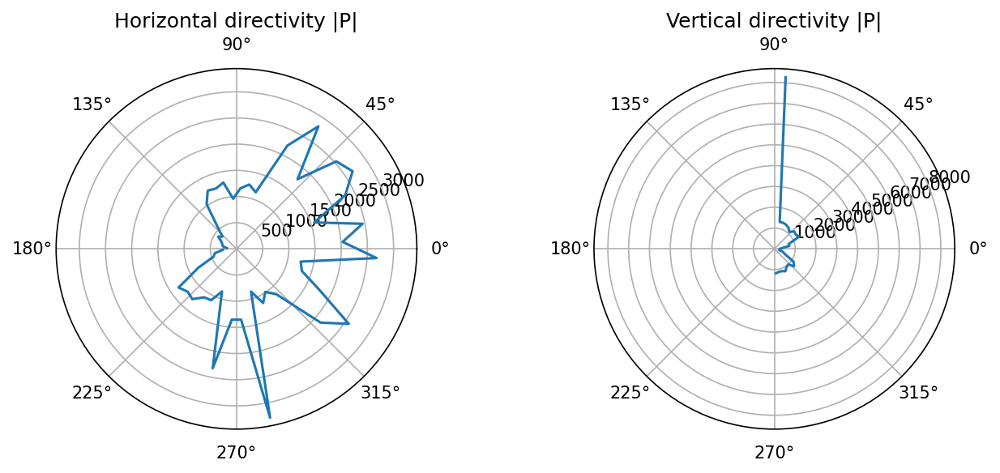

/Users/marcialsanchis/miniconda3/envs/surd/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1290: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
/Users/marcialsanchis/miniconda3/envs/surd/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1290: RuntimeWarning: invalid value encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
/Users/marcialsanchis/miniconda3/envs/surd/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1291: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/Users/marcialsanchis/miniconda3/envs/surd/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1291: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/Users/marcialsanchis/miniconda3/envs/surd/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1292: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/Users/marcialsanchi

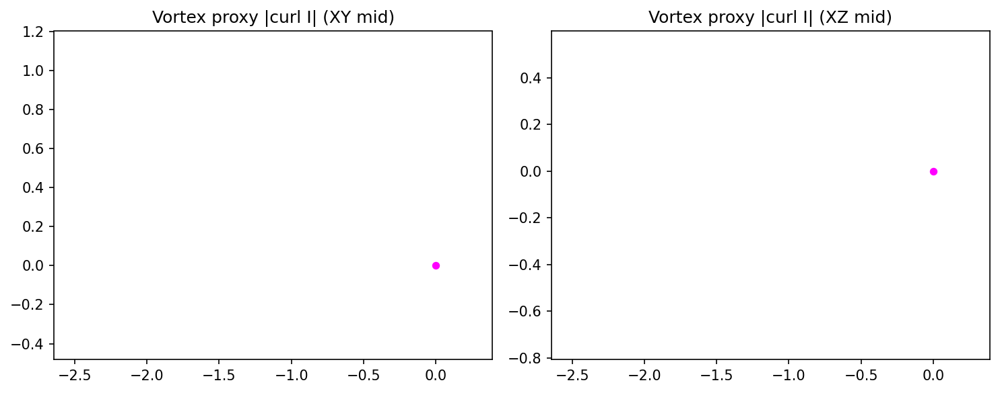

In [ ]:
# Uses current frequency from the last loop iteration if available
# If running standalone, set f0, pos, P, U first.

# Radial profiles (binned)
r = np.linalg.norm(pos, axis=1)
Pmag = np.abs(P)
I = np.real(0.5 * P[:,None] * np.conj(U))
Imag = np.linalg.norm(I, axis=1)

bins = np.linspace(r.min(), r.max(), 16)
bin_cent = 0.5*(bins[:-1]+bins[1:])
def binned_stat(x, y):
    out=[]
    for i in range(len(bins)-1):
        m = (x>=bins[i]) & (x<bins[i+1])
        out.append(np.median(y[m]) if np.any(m) else np.nan)
    return np.array(out)

p_med = binned_stat(r, Pmag)
i_med = binned_stat(r, Imag)

fig, ax = plt.subplots(1,1, figsize=(5.5,4), dpi=150)
ax.plot(bin_cent, p_med, '-o', label='|P| median')
ax.plot(bin_cent, i_med, '-o', label='|I| median')
ax.set_xlabel('radius [m]')
ax.set_ylabel('magnitude')
ax.set_title(f'{f0:.0f} Hz radial profiles')
ax.legend(); plt.tight_layout(); plt.show()

# Directivity lobes (polar) from measured points
theta = np.arctan2(pos[:,1], pos[:,0])  # horizontal angle
phi = np.arctan2(pos[:,2], np.sqrt(pos[:,0]**2 + pos[:,1]**2))  # elevation

def polar_binned(angle, val, n=36):
    bins = np.linspace(-np.pi, np.pi, n+1)
    angc = 0.5*(bins[:-1]+bins[1:])
    out=[]
    for i in range(n):
        m = (angle>=bins[i]) & (angle<bins[i+1])
        out.append(np.median(val[m]) if np.any(m) else np.nan)
    return angc, np.array(out)

ang_h, pol_h = polar_binned(theta, Pmag, n=48)
ang_v, pol_v = polar_binned(phi, Pmag, n=48)

fig = plt.figure(figsize=(9,4), dpi=150)
ax1 = fig.add_subplot(1,2,1, projection='polar')
ax1.plot(ang_h, pol_h); ax1.set_title('Horizontal directivity |P|')
ax2 = fig.add_subplot(1,2,2, projection='polar')
ax2.plot(ang_v, pol_v); ax2.set_title('Vertical directivity |P|')
plt.tight_layout(); plt.show()

# Vortex proxy: curl of interpolated intensity on grid mid‑planes
(xc, yc, zc), Pgrid = predict_green_grid(pos, P, f0, grid_n=36, n_src=1000, lam=1e-3)
Pgrid = smooth_complex_grid(Pgrid, sigma=1.0)
Pmag_grid = np.abs(Pgrid)
Igrid = interpolate_I_grid(pos, I, xc, yc, zc, neighbors=140, smoothing=0.3)

# compute curl on the grid (finite differences)
eps = 1e-6

# fill NaNs before gradients
Igrid = np.nan_to_num(Igrid, nan=0.0)

# safe grid spacings
dx = np.gradient(xc)
dy = np.gradient(yc)
dz = np.gradient(zc)
Ix = Igrid[:,:,:,0]; Iy = Igrid[:,:,:,1]; Iz = Igrid[:,:,:,2]
dx = np.maximum(dx, eps)
dy = np.maximum(dy, eps)
dz = np.maximum(dz, eps)

dIy_dz = np.gradient(Iy, dz, axis=2)
dIz_dy = np.gradient(Iz, dy, axis=1)
dIz_dx = np.gradient(Iz, dx, axis=0)
dIx_dz = np.gradient(Ix, dz, axis=2)
dIx_dy = np.gradient(Ix, dy, axis=1)
dIy_dx = np.gradient(Iy, dx, axis=0)
curl_x = dIz_dy - dIy_dz
curl_y = dIx_dz - dIz_dx
curl_z = dIy_dx - dIx_dy
curl_mag = np.sqrt(curl_x**2 + curl_y**2 + curl_z**2)

iz = len(zc)//2
iy = len(yc)//2
fig, axes = plt.subplots(1,2, figsize=(10,4), dpi=150)
X,Y = np.meshgrid(xc, yc, indexing='xy')
axes[0].contourf(X,Y,curl_mag[:,:,iz].T,levels=30,cmap='inferno')
axes[0].scatter([0],[0],s=20,c='magenta')
axes[0].set_title('Vortex proxy |curl I| (XY mid)')
X,Zm = np.meshgrid(xc, zc, indexing='xy')
axes[1].contourf(X,Zm,curl_mag[:,iy,:].T,levels=30,cmap='inferno')
axes[1].scatter([0],[0],s=20,c='magenta')
axes[1].set_title('Vortex proxy |curl I| (XZ mid)')
plt.tight_layout(); plt.show()


## Directivity (mf_pipeline style, smooth + dB)
We fit SH on all measured points, evaluate on a single spherical surface, and plot
clean horizontal/vertical polars (linear + dB), matching the original pipeline style.


In [ ]:
# Helper for lon/lat grids
def lonlat_to_xyz(lon_deg, lat_deg, r=1.0):
    lon, lat = np.meshgrid(np.deg2rad(lon_deg), np.deg2rad(lat_deg), indexing='xy')
    x = r * np.cos(lat) * np.cos(lon)
    y = r * np.cos(lat) * np.sin(lon)
    z = r * np.sin(lat)
    return x, y, z


### Directivity sanity checks
Prints dominant intensity direction and peak lobe angles so we can validate orientation.


In [ ]:
# Sanity checks for directivity orientation
I = np.real(0.5 * P[:,None] * np.conj(U))
cov = I.T @ I / max(len(I)-1, 1)
w, v = np.linalg.eigh(cov)
vdir = v[:, np.argmax(w)]
print('Dominant intensity dir (x,y,z):', vdir)

# Check lobes at r=1.0 m if available
try:
    lon_deg, lat_deg, V = eval_on_lonlat_map(a, k, 1.0, lmax, res_lon=361, res_lat=181)
    Vmag = np.abs(V)
    lon_h, Vh = horizontal_polar_from_map(lon_deg, lat_deg, Vmag, elev_deg=0.0)
    lat_v, Vv = vertical_polar_from_map(lon_deg, lat_deg, Vmag, az_deg=0.0)
    print('Peak horizontal angle (deg):', lon_h[np.argmax(Vh)])
    print('Peak vertical angle (deg):', lat_v[np.argmax(Vv)])
except Exception as e:
    print('Directivity check skipped:', e)


Dominant intensity dir (x,y,z): [-9.91139080e-01 -1.32821655e-12 -1.32828178e-01]
Peak horizontal angle (deg): -85.0
Peak vertical angle (deg): -52.0


TypeError: 'PolarAxes' object is not subscriptable

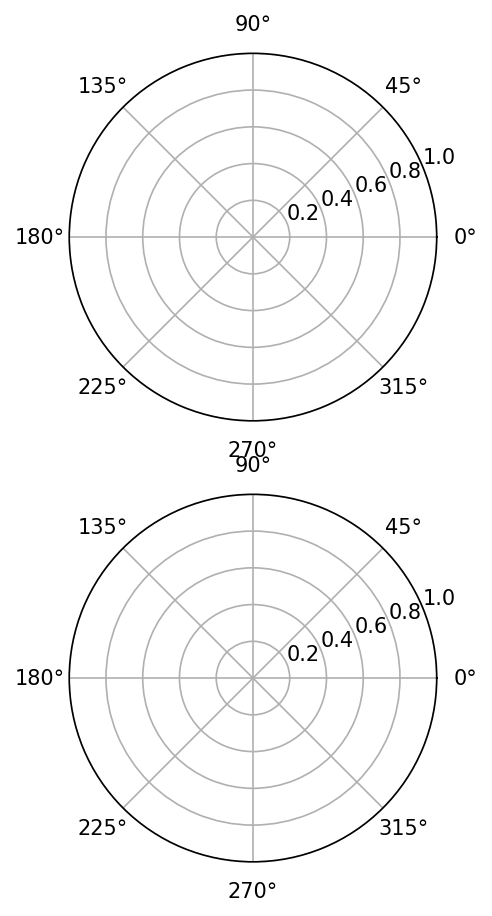

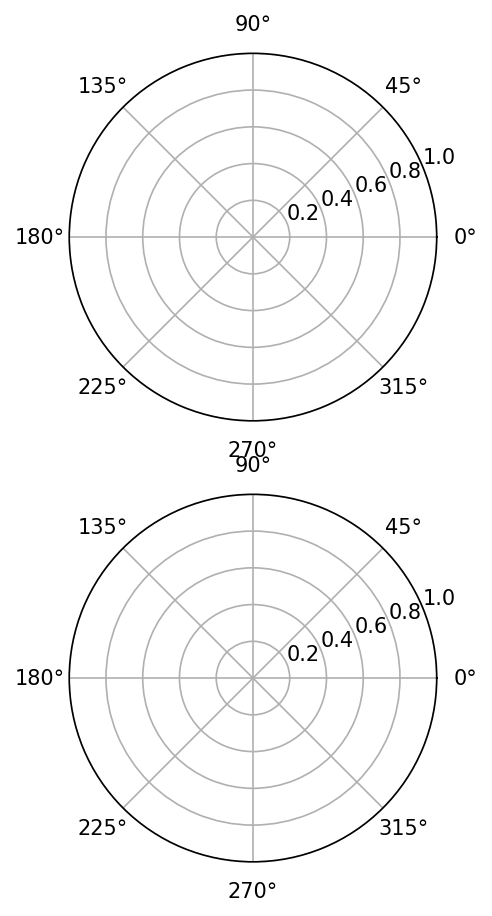

In [ ]:
from mf_pipeline.mf_directivity import (
    angles_from_pos, fit_complex_SH_nearfield, SHFitOptions,
    eval_on_lonlat_map, horizontal_polar_from_map, vertical_polar_from_map
)
from scipy.ndimage import gaussian_filter

def to_db(x):
    x = np.maximum(x, 1e-12)
    return 20.0 * np.log10(x)

# single radius for clean lobes
k = 2.0 * np.pi * f0 / 343.0
lmax = 6
r = np.linalg.norm(pos, axis=1)
r_eval = np.percentile(r, 60)

# optional mild clipping to reduce outliers
P_use = P.copy()
pclip = np.percentile(np.abs(P_use), 99.5)
P_use[np.abs(P_use) > pclip] *= pclip / np.maximum(np.abs(P_use[np.abs(P_use) > pclip]), 1e-12)

r_all, th_all, ph_all = angles_from_pos(pos, np.zeros(3))
a = fit_complex_SH_nearfield(P_use, r_all, th_all, ph_all, k, SHFitOptions(lmax=lmax, lam=1e-3))

lon_deg, lat_deg, V = eval_on_lonlat_map(a, k, r_eval, lmax, res_lon=361, res_lat=181)
Vmag = gaussian_filter(np.abs(V), sigma=1.2)

lon_h, Vh = horizontal_polar_from_map(lon_deg, lat_deg, Vmag, elev_deg=0.0)
lat_v, Vv = vertical_polar_from_map(lon_deg, lat_deg, Vmag, az_deg=0.0)
Vh = Vh / (Vh.max() + 1e-12)
Vv = Vv / (Vv.max() + 1e-12)

fig, (axh, axv) = plt.subplots(1, 2, figsize=(8, 4), dpi=150, subplot_kw={'projection': 'polar'})
axh.plot(np.deg2rad(lon_h), Vh)
axv.plot(np.deg2rad(lat_v), Vv)
axh.set_title(f'Horizontal r={r_eval:.2f} m')
axv.set_title(f'Vertical r={r_eval:.2f} m')
plt.tight_layout(); plt.show()

fig, (axh_db, axv_db) = plt.subplots(1, 2, figsize=(8, 4), dpi=150, subplot_kw={'projection': 'polar'})
axh_db.plot(np.deg2rad(lon_h), to_db(Vh))
axv_db.plot(np.deg2rad(lat_v), to_db(Vv))
axh_db.set_title(f'Horizontal r={r_eval:.2f} m (dB)')
axv_db.set_title(f'Vertical r={r_eval:.2f} m (dB)')
plt.tight_layout(); plt.show()
